# Projeto de Probabilidade e Estatística: Análise de Apostas Digitais no Brasil
## Linha de Pesquisa 1: O Perfil do Apostador Brasileiro
### Base de Dados: Pesquisa TIC Domicílios 2025 (Cetic.br / NIC.br)

---

### Contextualização e Motivação
Nos últimos anos, o Brasil experimentou uma expansão sem precedentes no mercado de apostas e jogos de azar online (*bets*, cassinos virtuais como o *Jogo do Tigrinho*, rifas digitais em redes sociais e loterias eletrônicas). A popularização acelerada desse ecossistema transformou-o em um tema central nos debates sobre finanças familiares, economia comportamental e saúde pública.

A pesquisa **TIC Domicílios 2025**, conduzida pelo Centro Regional de Estudos para o Desenvolvimento da Sociedade da Informação (**Cetic.br**), incorporou de maneira pioneira um bloco investigativo dedicado a mensurar as práticas de apostas online pela população brasileira (**Módulo C14**).

### Estrutura Global do Projeto
O projeto está organizado em cinco fases sequenciais:
1. **Fase 1: Preparação, Limpeza e Pré-processamento dos Dados (Executada nesta etapa)**
2. **Fase 2: Análise Exploratória de Dados (EDA) e Visualização**
3. **Fase 3: Inferência Estatística e Testes de Hipóteses**
4. **Fase 4: Modelagem Multivariada (Regressão Logística)**
5. **Fase 5: Síntese e Conclusões Estatísticas**

---
## FASE 1: Preparação, Limpeza e Pré-processamento dos Dados
Nesta primeira fase, construímos a fundação de todo o projeto:
* Configuração do ecossistema computacional (`pandas`, `numpy`);
* Carregamento seletivo e otimizado da base de microdados (reduzindo centenas de colunas para o escopo essencial de estudo);
* Tratamento de códigos sentinela do Cetic.br (`97 = Não sabe`, `98 = Não respondeu`, `99 = Não se aplica`);
* Decodificação das variáveis codificadas com base no Dicionário Oficial de Variáveis da TIC Domicílios 2025;
* Engenharia de atributos (*Feature Engineering*) criando indicadores analíticos (ex.: *poliapostadores*, contagem de modalidades);
* Validação de integridade e exportação da base tratada para as fases subsequentes.


### 1.1 Configuração do Ambiente e Importação de Bibliotecas


In [1]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd

# Ajustes de exibição do Pandas para relatórios analíticos
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

print("✓ Ambiente configurado com sucesso! Bibliotecas importadas.")


✓ Ambiente configurado com sucesso! Bibliotecas importadas.


### 1.2 Leitura Otimizada dos Microdados
O arquivo original possui mais de 24 mil observações e centenas de variáveis (~73 MB). Para otimizar o consumo de memória e a velocidade de processamento, realizamos uma leitura seletiva via `usecols`, tratando o delimitador ponto e vírgula (`;`) e a vírgula como separador decimal (`decimal=','`), necessária para a correta conversão do peso amostral (`PESO`).


In [2]:
# Localiza a raiz do projeto tanto ao executar daqui quanto a partir da raiz.
project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / 'bets').exists():
    project_root = project_root.parent

csv_path = project_root / 'bets/tic_domicilios/tic_domicilios_2025_individuos_base_de_microdados_v1.0.csv'

# Mapeamento e seleção das variáveis analíticas
colunas_selecionadas = [
    # Identificadores e Amostragem Probabilística
    'QUEST', 'ID_DOMICILIO', 'ID_MORADOR', 'PESO',
    
    # Módulo C14: Apostas e Jogos Digitais (Últimos 3 meses)
    'C14_A',       # Loteria federal online (Mega-Sena, etc.)
    'C14_B',       # Cassino online (Jogo do Tigrinho, etc.)
    'C14_C',       # Apostas esportivas (Bet365, Betano, Superbet, etc.)
    'C14_D',       # Rifa digital / sorteio em rede social ou app
    'C14_AGREG',   # Indicador agregado: Fez algum tipo de aposta
    
    # Perfil Sociodemográfico
    'SEXO', 'IDADE', 'FAIXA_ETARIA', 'GRAU_INST_1', 'RACA', 'RELIGIAO',
    
    # Condição Econômica e Inserção no Mercado de Trabalho
    'CLASSE_2015', 'RENDA_FAMILIAR_2', 'RENDA_PESSOAL', 'PEA_2', 'TIPO_OCUP',
    
    # Recorte Geográfico
    'COD_REGIAO_2', 'AREA', 'COD_UF',
    
    # Comportamento Digital e Meios de Acesso
    'C1',                # Já usou a internet
    'C3',                # Última utilização da internet
    'C4',                # Frequência de acesso à internet
    'C5_DISPOSITIVOS',   # Exclusividade móvel (apenas celular vs PC)
    'C8_H',              # Realização de transações financeiras online
    'C8_I',              # Uso de pagamentos via Pix
    'C9_A',              # Prática de jogos eletrônicos online
    'TC4B_B',            # Consumo de vídeos esportivos online
    'TC4B_I'             # Consumo de vídeos de influenciadores digitais
]

print(f"Carregando {len(colunas_selecionadas)} variáveis selecionadas...")
df_raw = pd.read_csv(csv_path, sep=';', usecols=colunas_selecionadas, decimal=',')

print("✓ Microdados carregados com sucesso!")
print(f"Dimensões: {df_raw.shape[0]:,} respondentes (indivíduos) e {df_raw.shape[1]} atributos.")


Carregando 32 variáveis selecionadas...
✓ Microdados carregados com sucesso!
Dimensões: 24,535 respondentes (indivíduos) e 32 atributos.


### 1.3 Tratamento de Códigos Especiais e Valores Sentinela
A metodologia das pesquisas Cetic.br emprega códigos sentinela padronizados:
* `97`: Não sabe
* `98`: Não respondeu / Recusa
* `99`: Não se aplica (indivíduos não elegíveis para o filtro da pergunta, por exemplo, não internautas)

**Critérios de Tratamento:**
1. **Modalidades de Aposta (`C14_A`, `C14_B`, `C14_C`, `C14_D`):**
   * O código `1` indica "Sim" (praticou a modalidade).
   * O código `0` indica "Não" (não praticou entre os elegíveis).
   * O código `99` (Não se aplica) refere-se a indivíduos que não usaram internet nos últimos 3 meses. No universo da população geral, esses indivíduos **não realizaram apostas digitais** (imputado logicamente como `0`).
   * Os códigos de recusa/desconhecimento (`97` e `98`) representam menos de $0,1\%$ das observações e são convertidos em `NaN`.
2. **Atividades de Comportamento Digital (`C8_H`, `C8_I`, `C9_A`, etc.):**
   * Aplicamos o mesmo princípio: `1 = Sim`, `0 / 99 = Não`, `97 / 98 = NaN`.


In [3]:
df = df_raw.copy()

modalidades_aposta = ['C14_A', 'C14_B', 'C14_C', 'C14_D']

for col in modalidades_aposta:
    # 97 e 98 -> NaN (respostas não válidas)
    # 99 -> 0 (não usou internet nos últimos 3 meses, logo não apostou online)
    df[col] = df[col].replace({97: np.nan, 98: np.nan, 99: 0})

# O indicador C14_AGREG já é fornecido pelo Cetic.br com 1=Apostou e 0=Não apostou
df['C14_AGREG'] = df['C14_AGREG'].astype(int)

# Tratamento para hábitos digitais auxiliares
habitos_digitais = ['C8_H', 'C8_I', 'C9_A', 'TC4B_B', 'TC4B_I']
for col in habitos_digitais:
    df[col] = df[col].replace({97: np.nan, 98: np.nan, 99: 0})

print("✓ Códigos sentinela tratados com rigor metodológico.")


✓ Códigos sentinela tratados com rigor metodológico.


### 1.4 Decodificação e Mapeamento Categórico Oficial
Convertemos os códigos numéricos em categorias descritivas baseadas no **Dicionário Oficial da TIC Domicílios 2025**. Além disso, ordenamos variáveis ordinais (como classes sociais e faixas etárias) para facilitar as análises exploratórias e inferenciais.


In [4]:
# Dicionários de decodificação
map_sexo = {1: 'Masculino', 2: 'Feminino'}

map_faixa_etaria = {
    1: '10 a 15 anos',
    2: '16 a 24 anos',
    3: '25 a 34 anos',
    4: '35 a 44 anos',
    5: '45 a 59 anos',
    6: '60 anos ou mais'
}

map_instrucao = {
    1: 'Analfabeto/Ed. Infantil',
    2: 'Fundamental',
    3: 'Médio',
    4: 'Superior'
}

map_classe = {
    1: 'Classe A',
    2: 'Classe B',
    3: 'Classe C',
    4: 'Classe DE'
}

map_renda_familiar = {
    1: 'Até 1 SM',
    2: 'Mais de 1 a 2 SM',
    3: 'Mais de 2 a 3 SM',
    4: 'Mais de 3 a 5 SM',
    5: 'Mais de 5 a 10 SM',
    6: 'Mais de 10 SM',
    7: 'Sem renda',
    97: np.nan,
    98: np.nan
}

map_regiao = {
    1: 'Sudeste',
    2: 'Nordeste',
    3: 'Sul',
    4: 'Norte',
    5: 'Centro-Oeste'
}

map_area = {
    1: 'Urbana',
    2: 'Rural'
}

map_raca = {
    1: 'Branca',
    2: 'Preta',
    3: 'Parda',
    4: 'Amarela',
    5: 'Indígena',
    98: np.nan
}

map_pea = {
    1: 'Na força de trabalho',
    2: 'Fora da força de trabalho'
}

map_ocup = {
    1: 'Formal',
    2: 'Informal',
    4: 'Não se aplica'
}

map_dispositivos = {
    1: 'Apenas Computador',
    2: 'Apenas Celular',
    3: 'Ambos (PC e Celular)',
    4: 'Nenhum desses',
    99: 'Não se aplica'
}

# Criação das colunas descritivas
df['sexo_desc'] = df['SEXO'].map(map_sexo)
df['faixa_etaria_desc'] = pd.Categorical(df['FAIXA_ETARIA'].map(map_faixa_etaria), 
                                        categories=list(map_faixa_etaria.values()), ordered=True)
df['escolaridade_desc'] = pd.Categorical(df['GRAU_INST_1'].map(map_instrucao),
                                        categories=list(map_instrucao.values()), ordered=True)
df['classe_desc'] = pd.Categorical(df['CLASSE_2015'].map(map_classe),
                                   categories=['Classe DE', 'Classe C', 'Classe B', 'Classe A'], ordered=True)
df['renda_familiar_desc'] = df['RENDA_FAMILIAR_2'].map(map_renda_familiar)
df['regiao_desc'] = df['COD_REGIAO_2'].map(map_regiao)
df['area_desc'] = df['AREA'].map(map_area)
df['raca_desc'] = df['RACA'].map(map_raca)
df['situacao_trabalho_desc'] = df['PEA_2'].map(map_pea)
df['tipo_ocupacao_desc'] = df['TIPO_OCUP'].map(map_ocup)
df['dispositivos_desc'] = df['C5_DISPOSITIVOS'].map(map_dispositivos)

print("✓ Variáveis categóricas e ordinais mapeadas com sucesso.")


✓ Variáveis categóricas e ordinais mapeadas com sucesso.


### 1.5 Engenharia de Recursos (*Feature Engineering*)
Construímos novos atributos analíticos para segmentar os apostadores:
1. **`qtd_modalidades`**: Soma do número de modalidades em que o indivíduo apostou (varia de 0 a 4);
2. **`poliapostador`**: Variável indicadora binária para quem aposta em **2 ou mais** modalidades simultâneas;
3. **`status_aposta`**: Rótulo textual direto (*Apostador* vs *Não Apostador*);
4. **Colunas individuais renomeadas** com títulos explícitos (`aposta_loteria`, `aposta_cassino`, `aposta_esportiva`, `aposta_rifa`).


In [5]:
# Quantidade de modalidades praticadas pelo indivíduo
df['qtd_modalidades'] = df[modalidades_aposta].sum(axis=1)

# Poliapostador (engajamento em múltiplas modalidades)
df['poliapostador'] = (df['qtd_modalidades'] >= 2).astype(int)

# Rótulo de status de aposta
df['status_aposta'] = df['C14_AGREG'].map({1: 'Apostador', 0: 'Não Apostador'})

# Renomeação semântica das modalidades
df['aposta_loteria'] = df['C14_A']
df['aposta_cassino'] = df['C14_B']
df['aposta_esportiva'] = df['C14_C']
df['aposta_rifa'] = df['C14_D']

print("--- Distribuição da Quantidade de Modalidades de Aposta ---")
print(df['qtd_modalidades'].value_counts().sort_index())

print("\n--- Proporção de Poliapostadores na Amostra Geral ---")
pct_poli = df['poliapostador'].value_counts(normalize=True) * 100
for val, p in pct_poli.items():
    lbl = "Poliapostador (2+ tipos)" if val == 1 else "Aposta em 1 ou nenhuma modalidade"
    print(f"{lbl}: {p:.2f}%")


--- Distribuição da Quantidade de Modalidades de Aposta ---
qtd_modalidades
0.000    20699
1.000     2398
2.000      974
3.000      356
4.000      108
Name: count, dtype: int64

--- Proporção de Poliapostadores na Amostra Geral ---
Aposta em 1 ou nenhuma modalidade: 94.14%
Poliapostador (2+ tipos): 5.86%


### 1.6 Auditoria e Resumo Estatístico dos Dados Tratados
Inspecionamos a integridade amostral, a distribuição da idade, pesos amostrais e geramos a primeira tabela de contingência exploratória.


In [6]:
print("==================================================")
print("             AUDITORIA DO DATASET TRATADO         ")
print("==================================================")
print(f"Total de Respondentes: {len(df):,}")
print(f"Total de Variáveis Finais: {df.shape[1]}")
print(f"Apostadores Identificados na Amostra: {df['C14_AGREG'].sum():,} ({df['C14_AGREG'].mean():.2%})")

print("\n--- Resumo Estatístico das Variáveis Contínuas ---")
print(df[['IDADE', 'PESO', 'qtd_modalidades']].describe())

print("\n--- Prevalência por Modalidade de Aposta (Amostra Bruta) ---")
mod_stats = pd.DataFrame({
    'Modalidade': ['Cassino Online (Tigrinho)', 'Rifa Digital / Sorteio', 'Apostas Esportivas (Bets)', 'Loteria Federal Online'],
    'Respondentes (Sim)': [df['aposta_cassino'].sum(), df['aposta_rifa'].sum(), df['aposta_esportiva'].sum(), df['aposta_loteria'].sum()]
})
mod_stats['% Amostra Total'] = (mod_stats['Respondentes (Sim)'] / len(df) * 100).round(2).astype(str) + '%'
print(mod_stats.to_string(index=False))

print("\n--- Tabela de Frequência Inicial: Gênero vs Status de Aposta ---")
tabela_sexo = pd.crosstab(df['sexo_desc'], df['status_aposta'], margins=True, margins_name="Total")
tabela_sexo_pct = pd.crosstab(df['sexo_desc'], df['status_aposta'], normalize='index').mul(100).round(2)
print(tabela_sexo)
print("\nPercentual dentro de cada gênero:")
print(tabela_sexo_pct.astype(str) + '%')


             AUDITORIA DO DATASET TRATADO         
Total de Respondentes: 24,535
Total de Variáveis Finais: 50
Apostadores Identificados na Amostra: 3,836 (15.63%)

--- Resumo Estatístico das Variáveis Contínuas ---
          IDADE       PESO  qtd_modalidades
count 24535.000  24535.000        24535.000
mean     45.104   7556.904            0.238
std      19.515  23089.258            0.633
min      10.000      0.817            0.000
25%      28.000    793.627            0.000
50%      45.000   2205.927            0.000
75%      61.000   6175.259            0.000
max     100.000 873037.544            4.000

--- Prevalência por Modalidade de Aposta (Amostra Bruta) ---
               Modalidade  Respondentes (Sim) % Amostra Total
Cassino Online (Tigrinho)            1885.000           7.68%
   Rifa Digital / Sorteio            1489.000           6.07%
Apostas Esportivas (Bets)            1362.000           5.55%
   Loteria Federal Online            1110.000           4.52%

--- Tabela de F

### 1.7 Exportação da Base Pré-processada
Exportamos o DataFrame final tratado em arquivo CSV (`tic_domicilios_processada_apostas.csv`). Dessa forma, as **Fases 2 (EDA)**, **Fase 3 (Testes de Hipóteses)** e **Fase 4 (Regressão)** poderão carregar a base limpa de maneira instantânea.


In [7]:
output_csv = project_root / 'bets/tic_domicilios/tic_domicilios_processada_apostas.csv'
df.to_csv(output_csv, index=False, sep=';', decimal='.')

tam_mb = os.path.getsize(output_csv) / (1024 * 1024)
print(f"✓ Base processada gravada com sucesso em '{output_csv}' ({tam_mb:.2f} MB).")
print("\n>>> FASE 1 CONCLUÍDA COM SUCESSO! <<<")
print("Prontos para avançar para a FASE 2: Análise Exploratória de Dados (EDA) e Visualização.")


✓ Base processada gravada com sucesso em '/home/lucas/Aulas/Probabilidade e Estatistisca/Projeto Final/bets/tic_domicilios/tic_domicilios_processada_apostas.csv' (6.33 MB).

>>> FASE 1 CONCLUÍDA COM SUCESSO! <<<
Prontos para avançar para a FASE 2: Análise Exploratória de Dados (EDA) e Visualização.


---
## FASE 2: Análise Exploratória de Dados (EDA) e Visualização

Nesta fase, exploramos profundamente a base de dados tratada para responder às principais perguntas sobre o **perfil do apostador digital no Brasil**:
1. **Panorama e Prevalência Geral:** Qual a proporção de brasileiros que aposta e quais as modalidades mais populares (amostral e expandida pelo peso amostral)?
2. **Perfil Demográfico:** Como as apostas se distribuem por **gênero**, **idade** e **ciclo de vida**?
3. **Perfil Socioeconômico:** Qual a relação entre aposta digital, **classes sociais (Critério Brasil)**, **escolaridade** e **trabalho informal**?
4. **Recorte Geográfico:** Existem assimetrias regionais significativas no Brasil ou disparidades entre áreas urbanas e rurais?
5. **O Ecossistema Digital da Aposta:** Como o uso de **Pix**, o acesso exclusivo por **celular (*mobile-only*)** e o consumo de **vídeos de influenciadores digitais** impulsionam as apostas?
6. **Poliapostadores e Sobreposição:** Quantos brasileiros apostam em mais de uma modalidade simultaneamente e quais jogos costumam andar juntos?


### 2.1 Panorama Geral: Prevalência Amostral vs Estimativa Ponderada
Em pesquisas amostrais complexas como a TIC Domicílios, cada indivíduo representa um determinado número de pessoas na população brasileira através da variável de peso amostral $w_i$ (`PESO`).
A estimativa ponderada da proporção populacional é dada por:

$$\hat{P} = \frac{\sum_{i=1}^n w_i \cdot Y_i}{\sum_{i=1}^n w_i}$$

onde $Y_i \in \{0, 1\}$ indica a prática da modalidade. Abaixo comparamos a taxa amostral direta e a estimativa ponderada expandida para a população brasileira.


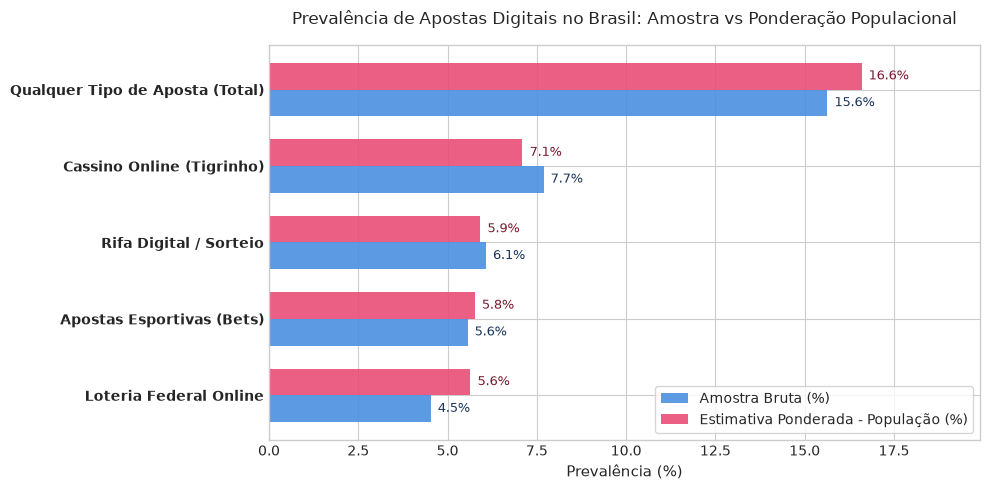

Tabela Detalhada de Prevalência:


'                     Modalidade  Taxa Amostral (%)  Taxa Ponderada (%)  População Estimada (milhões)\nQualquer Tipo de Aposta (Total)             15.635              16.590                        30.759\n      Cassino Online (Tigrinho)              7.687               7.097                        13.158\n         Rifa Digital / Sorteio              6.072               5.916                        10.969\n      Apostas Esportivas (Bets)              5.558               5.760                        10.680\n         Loteria Federal Online              4.527               5.639                        10.456'

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração do estilo gráfico
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Cálculo da prevalência amostral e ponderada
mods = {
    'Cassino Online (Tigrinho)': 'aposta_cassino',
    'Rifa Digital / Sorteio': 'aposta_rifa',
    'Apostas Esportivas (Bets)': 'aposta_esportiva',
    'Loteria Federal Online': 'aposta_loteria',
    'Qualquer Tipo de Aposta (Total)': 'C14_AGREG'
}

peso_total = df['PESO'].sum()
pop_brasil_proj = peso_total

resumo_prev = []
for label, col in mods.items():
    taxa_amostral = df[col].mean() * 100
    taxa_ponderada = (df[col] * df['PESO']).sum() / peso_total * 100
    total_proj = (df[col] * df['PESO']).sum()
    
    resumo_prev.append({
        'Modalidade': label,
        'Taxa Amostral (%)': taxa_amostral,
        'Taxa Ponderada (%)': taxa_ponderada,
        'População Estimada (milhões)': total_proj / 1e6
    })

df_prev = pd.DataFrame(resumo_prev).sort_values(by='Taxa Ponderada (%)', ascending=True)

# Visualização comparativa
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = range(len(df_prev))
width = 0.35

ax.barh([p - width/2 for p in y_pos], df_prev['Taxa Amostral (%)'], height=width, 
        label='Amostra Bruta (%)', color='#4A90E2', alpha=0.9)
ax.barh([p + width/2 for p in y_pos], df_prev['Taxa Ponderada (%)'], height=width, 
        label='Estimativa Ponderada - População (%)', color='#E94E77', alpha=0.9)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_prev['Modalidade'], fontweight='bold')
ax.set_xlabel('Prevalência (%)')
ax.set_title('Prevalência de Apostas Digitais no Brasil: Amostra vs Ponderação Populacional', pad=15)
ax.legend(loc='lower right', frameon=True)

# Rótulos nas barras
for p, (amostra, pond) in enumerate(zip(df_prev['Taxa Amostral (%)'], df_prev['Taxa Ponderada (%)'])):
    ax.text(amostra + 0.2, p - width/2, f'{amostra:.1f}%', va='center', fontsize=9, color='#1A365D')
    ax.text(pond + 0.2, p + width/2, f'{pond:.1f}%', va='center', fontsize=9, color='#7A1B30')

ax.set_xlim(0, max(df_prev['Taxa Ponderada (%)']) * 1.2)
plt.tight_layout()
plt.show()

print("Tabela Detalhada de Prevalência:")
display(df_prev.sort_values(by='Taxa Ponderada (%)', ascending=False).to_string(index=False))


### 2.2 O Perfil Demográfico: Disparidades de Gênero e Concentração Etária
Analisamos como as apostas se diferenciam entre **homens e mulheres** e como se comportam as **distribuições etárias** de cada modalidade.


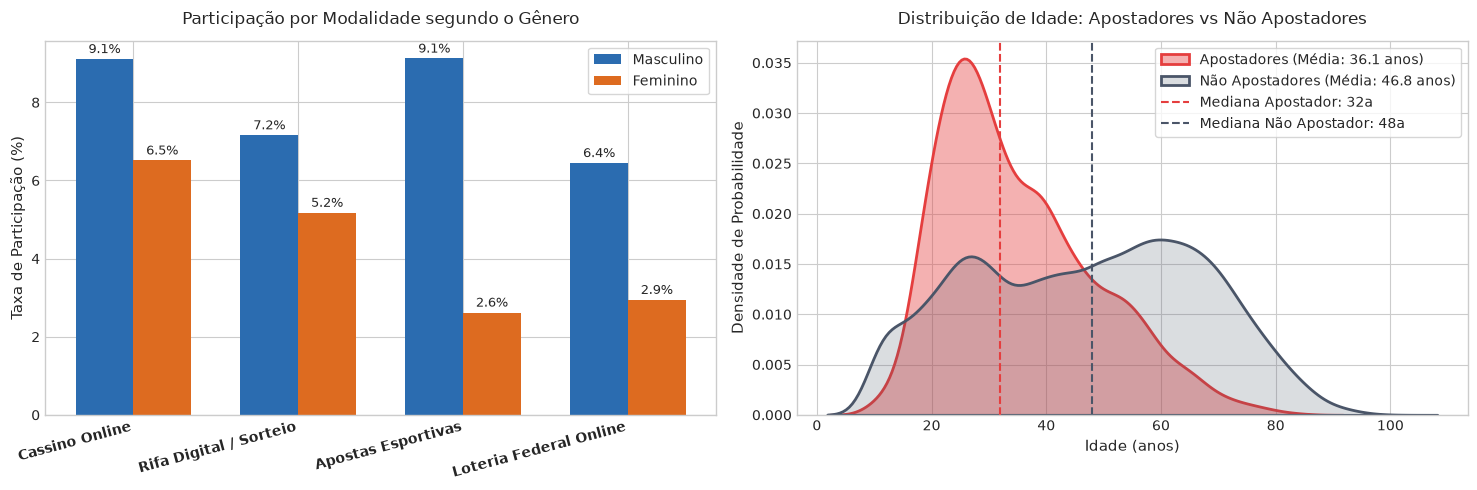

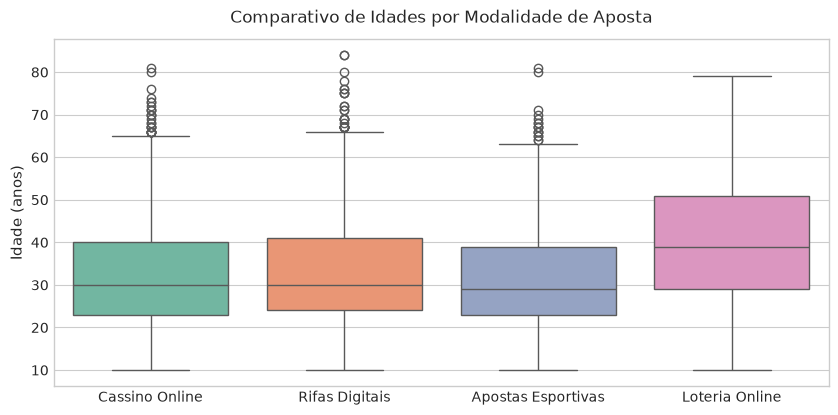

Resumo Numérico da Idade por Modalidade:
                     mean    std    50%    min    max
Modalidade                                           
Apostas Esportivas 31.706 11.210 29.000 10.000 81.000
Cassino Online     32.690 12.212 30.000 10.000 81.000
Loteria Online     40.680 13.922 39.000 10.000 79.000
Rifas Digitais     33.823 13.194 30.000 10.000 84.000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Taxa de adesão por modalidade separada por Sexo
genero_mods = []
for label, col in mods.items():
    if col != 'C14_AGREG':
        tx_m = df[df['sexo_desc'] == 'Masculino'][col].mean() * 100
        tx_f = df[df['sexo_desc'] == 'Feminino'][col].mean() * 100
        genero_mods.append({'Modalidade': label.split(' (')[0], 'Masculino': tx_m, 'Feminino': tx_f})

df_gen = pd.DataFrame(genero_mods)
x = np.arange(len(df_gen))
w = 0.35

axes[0].bar(x - w/2, df_gen['Masculino'], width=w, label='Masculino', color='#2B6CB0')
axes[0].bar(x + w/2, df_gen['Feminino'], width=w, label='Feminino', color='#DD6B20')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_gen['Modalidade'], rotation=15, ha='right', fontweight='bold')
axes[0].set_ylabel('Taxa de Participação (%)')
axes[0].set_title('Participação por Modalidade segundo o Gênero', pad=12)
axes[0].legend(frameon=True)

for i in x:
    axes[0].text(i - w/2, df_gen['Masculino'][i] + 0.15, f"{df_gen['Masculino'][i]:.1f}%", ha='center', fontsize=9)
    axes[0].text(i + w/2, df_gen['Feminino'][i] + 0.15, f"{df_gen['Feminino'][i]:.1f}%", ha='center', fontsize=9)

# 2. Distribuição Etária Contínua (KDE) Apostadores vs Não Apostadores
sns.kdeplot(data=df[df['status_aposta'] == 'Apostador']['IDADE'], ax=axes[1], 
            label='Apostadores (Média: 36.1 anos)', color='#E53E3E', fill=True, alpha=0.4, linewidth=2)
sns.kdeplot(data=df[df['status_aposta'] == 'Não Apostador']['IDADE'], ax=axes[1], 
            label='Não Apostadores (Média: 46.8 anos)', color='#4A5568', fill=True, alpha=0.2, linewidth=2)
axes[1].axvline(df[df['status_aposta'] == 'Apostador']['IDADE'].median(), color='#E53E3E', linestyle='--', label=f"Mediana Apostador: {df[df['status_aposta'] == 'Apostador']['IDADE'].median():.0f}a")
axes[1].axvline(df[df['status_aposta'] == 'Não Apostador']['IDADE'].median(), color='#4A5568', linestyle='--', label=f"Mediana Não Apostador: {df[df['status_aposta'] == 'Não Apostador']['IDADE'].median():.0f}a")
axes[1].set_xlabel('Idade (anos)')
axes[1].set_ylabel('Densidade de Probabilidade')
axes[1].set_title('Distribuição de Idade: Apostadores vs Não Apostadores', pad=12)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

# Boxplot de idade por modalidade específica
plt.figure(figsize=(10, 4.5))
dados_idade_mods = []
for label, col in [('Cassino Online', 'aposta_cassino'), ('Rifas Digitais', 'aposta_rifa'), 
                   ('Apostas Esportivas', 'aposta_esportiva'), ('Loteria Online', 'aposta_loteria')]:
    sub = df[df[col] == 1][['IDADE']].copy()
    sub['Modalidade'] = label
    dados_idade_mods.append(sub)

df_idade_mods = pd.concat(dados_idade_mods, ignore_index=True)
sns.boxplot(data=df_idade_mods, x='Modalidade', y='IDADE', palette='Set2')
plt.title('Comparativo de Idades por Modalidade de Aposta', pad=12)
plt.ylabel('Idade (anos)')
plt.xlabel('')
plt.show()

print("Resumo Numérico da Idade por Modalidade:")
print(df_idade_mods.groupby('Modalidade')['IDADE'].describe()[['mean', 'std', '50%', 'min', 'max']])


### 2.3 O Perfil Socioeconômico: Renda, Classes Sociais e Informalidade
Investigamos a hipótese da **vulnerabilidade socioeconômica**: como a propensão a apostar se comporta nas diferentes classes econômicas (Critério Brasil 2015), graus de escolaridade e inserção no mercado de trabalho (formal vs informal).


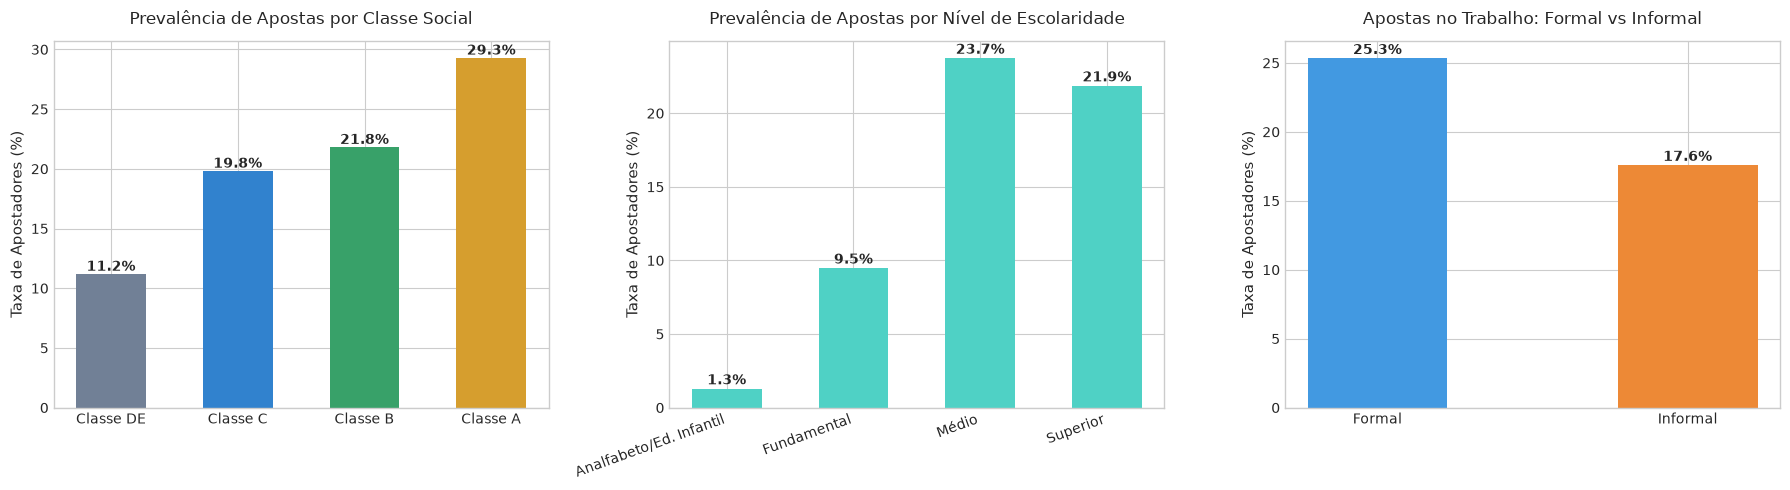

--- Decomposição das Modalidades nas Classes Econômicas Extrema (DE vs A) ---

Classe DE (Total: 12,385 indivíduos):
  • Cassino Online: 6.49%
  • Rifas: 4.05%
  • Bets Esportivas: 3.94%
  • Loteria: 2.42%

Classe A (Total: 123 indivíduos):
  • Cassino Online: 7.44%
  • Rifas: 10.74%
  • Bets Esportivas: 9.92%
  • Loteria: 16.53%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Taxa de Apostas por Classe Econômica
classe_order = ['Classe DE', 'Classe C', 'Classe B', 'Classe A']
tx_classe = df.groupby('classe_desc')['C14_AGREG'].mean().reindex(classe_order) * 100
bars1 = axes[0].bar(classe_order, tx_classe, color=['#718096', '#3182CE', '#38A169', '#D69E2E'], width=0.55)
axes[0].set_ylabel('Taxa de Apostadores (%)')
axes[0].set_title('Prevalência de Apostas por Classe Social', pad=12)
for bar in bars1:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, y + 0.3, f"{y:.1f}%", ha='center', fontweight='bold')

# 2. Taxa de Apostas por Nível de Escolaridade
escolaridade_order = ['Analfabeto/Ed. Infantil', 'Fundamental', 'Médio', 'Superior']
tx_esc = df.groupby('escolaridade_desc')['C14_AGREG'].mean().reindex(escolaridade_order) * 100
bars2 = axes[1].bar(escolaridade_order, tx_esc, color='#4FD1C5', width=0.55)
axes[1].set_ylabel('Taxa de Apostadores (%)')
axes[1].set_xticklabels(escolaridade_order, rotation=20, ha='right')
axes[1].set_title('Prevalência de Apostas por Nível de Escolaridade', pad=12)
for bar in bars2:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, y + 0.3, f"{y:.1f}%", ha='center', fontweight='bold')

# 3. Taxa de Apostas por Tipo de Ocupação no Trabalho
ocup_validas = df[df['tipo_ocupacao_desc'].isin(['Formal', 'Informal'])]
tx_ocup = ocup_validas.groupby('tipo_ocupacao_desc')['C14_AGREG'].mean() * 100
bars3 = axes[2].bar(tx_ocup.index, tx_ocup.values, color=['#4299E1', '#ED8936'], width=0.45)
axes[2].set_ylabel('Taxa de Apostadores (%)')
axes[2].set_title('Apostas no Trabalho: Formal vs Informal', pad=12)
for bar in bars3:
    y = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, y + 0.3, f"{y:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Decomposição de modalidades nas Classes DE vs A
print("--- Decomposição das Modalidades nas Classes Econômicas Extrema (DE vs A) ---")
for cl in ['Classe DE', 'Classe A']:
    sub = df[df['classe_desc'] == cl]
    print(f"\n{cl} (Total: {len(sub):,} indivíduos):")
    for lbl, col in [('Cassino Online', 'aposta_cassino'), ('Rifas', 'aposta_rifa'), 
                     ('Bets Esportivas', 'aposta_esportiva'), ('Loteria', 'aposta_loteria')]:
        print(f"  • {lbl}: {sub[col].mean()*100:.2f}%")


### 2.4 Panorama Geográfico: Distribuição Regional e Urbana vs Rural
Mapeamos a incidência das apostas pelas 5 macrorregiões do país e o contraste entre as zonas urbanas e rurais.


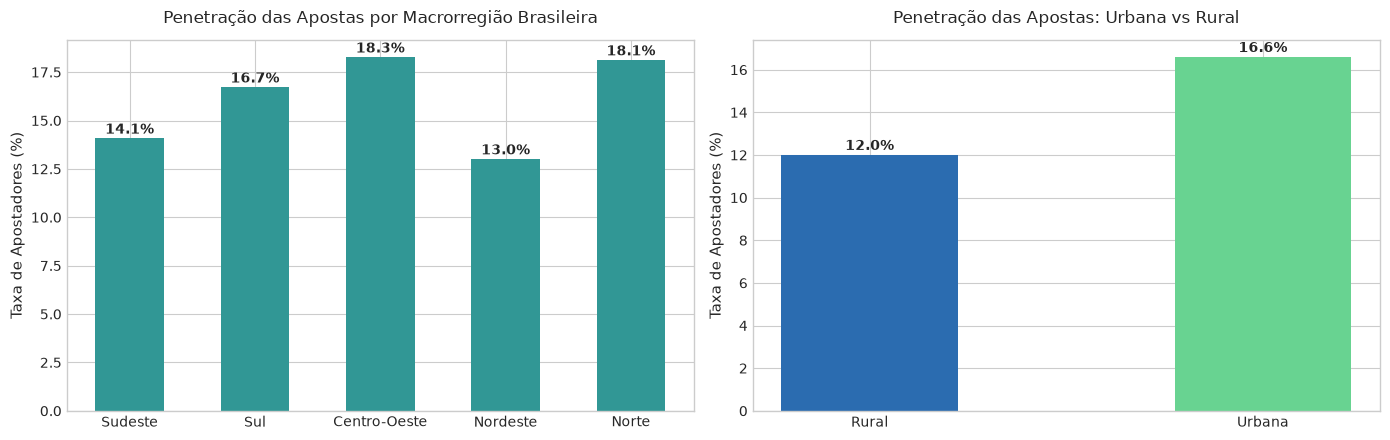

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Regiões do Brasil
reg_order = ['Sudeste', 'Sul', 'Centro-Oeste', 'Nordeste', 'Norte']
tx_reg = df.groupby('regiao_desc')['C14_AGREG'].mean().reindex(reg_order) * 100
axes[0].bar(reg_order, tx_reg, color='#319795', width=0.55)
axes[0].set_ylabel('Taxa de Apostadores (%)')
axes[0].set_title('Penetração das Apostas por Macrorregião Brasileira', pad=12)
for i, v in enumerate(tx_reg):
    axes[0].text(i, v + 0.25, f"{v:.1f}%", ha='center', fontweight='bold')

# 2. Área Urbana vs Rural
tx_area = df.groupby('area_desc')['C14_AGREG'].mean() * 100
axes[1].bar(tx_area.index, tx_area.values, color=['#2B6CB0', '#68D391'], width=0.45)
axes[1].set_ylabel('Taxa de Apostadores (%)')
axes[1].set_title('Penetração das Apostas: Urbana vs Rural', pad=12)
for i, v in enumerate(tx_area):
    axes[1].text(i, v + 0.25, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### 2.5 O Ecossistema Digital: O Papel do Pix, do Smartphone e dos Influenciadores Digitais
A infraestrutura tecnológica brasileira é apontada como catalisadora das apostas online. Avaliamos a relação empírica com:
* **Uso de Pix (`C8_I`);**
* **Dispositivo de Acesso Exclusivo por Celular (`C5_DISPOSITIVOS`);**
* **Consumo de Vídeos de Influenciadores Digitais (`TC4B_I`).**


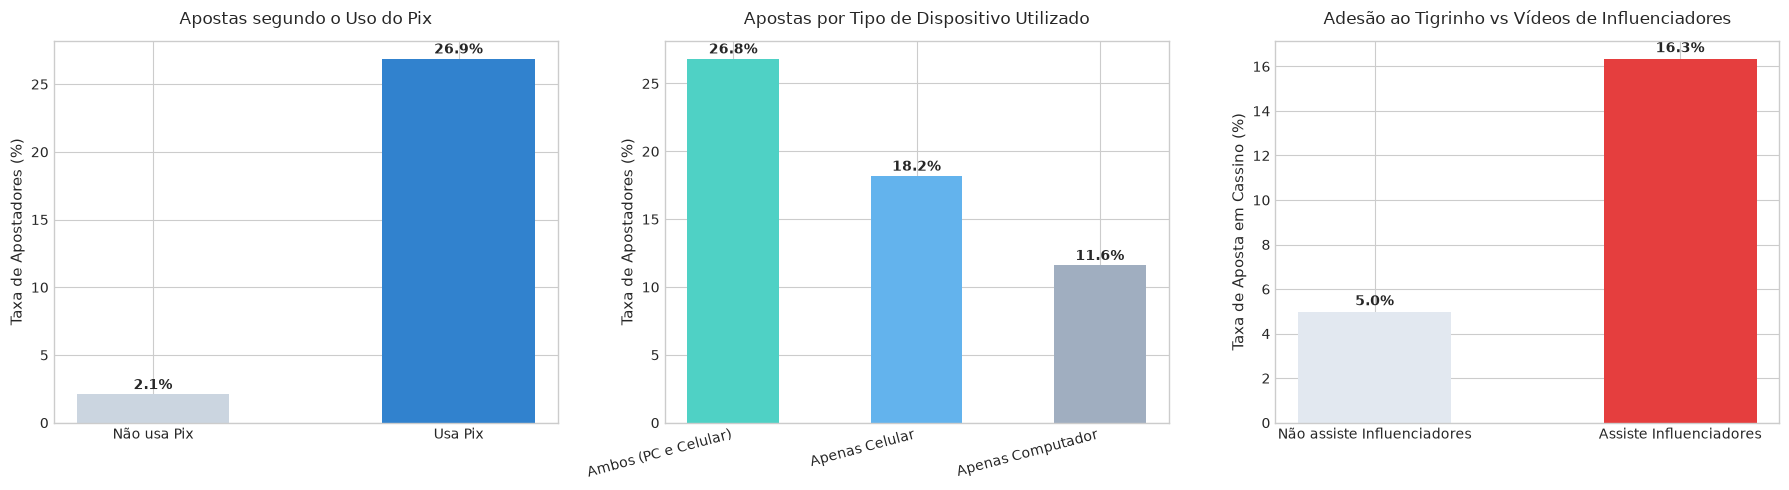

-> Razão de Prevalência: Indivíduos que assistem a influenciadores digitais têm 3.28x maior probabilidade de jogar no Cassino Online (Tigrinho).


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Pix e Apostas
tx_pix = df.groupby('C8_I')['C14_AGREG'].mean() * 100
axes[0].bar(['Não usa Pix', 'Usa Pix'], tx_pix.values, color=['#CBD5E0', '#3182CE'], width=0.5)
axes[0].set_ylabel('Taxa de Apostadores (%)')
axes[0].set_title('Apostas segundo o Uso do Pix', pad=12)
for i, v in enumerate(tx_pix):
    axes[0].text(i, v + 0.4, f"{v:.1f}%", ha='center', fontweight='bold')

# 2. Dispositivo de Acesso (Mobile-only vs PC)
disp_validos = df[df['dispositivos_desc'].isin(['Apenas Celular', 'Ambos (PC e Celular)', 'Apenas Computador'])]
tx_disp = disp_validos.groupby('dispositivos_desc')['C14_AGREG'].mean().sort_values(ascending=False) * 100
axes[1].bar(tx_disp.index, tx_disp.values, color=['#4FD1C5', '#63B3ED', '#A0AEC0'], width=0.5)
axes[1].set_ylabel('Taxa de Apostadores (%)')
axes[1].set_xticklabels(tx_disp.index, rotation=15, ha='right')
axes[1].set_title('Apostas por Tipo de Dispositivo Utilizado', pad=12)
for i, v in enumerate(tx_disp):
    axes[1].text(i, v + 0.4, f"{v:.1f}%", ha='center', fontweight='bold')

# 3. Influenciadores Digitais e Cassino Online (Tigrinho)
tx_infl = df.groupby('TC4B_I')['aposta_cassino'].mean() * 100
axes[2].bar(['Não assiste Influenciadores', 'Assiste Influenciadores'], tx_infl.values, 
            color=['#E2E8F0', '#E53E3E'], width=0.5)
axes[2].set_ylabel('Taxa de Aposta em Cassino (%)')
axes[2].set_title('Adesão ao Tigrinho vs Vídeos de Influenciadores', pad=12)
for i, v in enumerate(tx_infl):
    axes[2].text(i, v + 0.3, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Razão de prevalência calculada
rp_infl = tx_infl[1] / tx_infl[0]
print(f"-> Razão de Prevalência: Indivíduos que assistem a influenciadores digitais têm {rp_infl:.2f}x maior probabilidade de jogar no Cassino Online (Tigrinho).")


### 2.6 Sobreposição de Modalidades e Matriz de Correlação
Analisamos a intersecção entre as diferentes modalidades. Quando um indivíduo aposta em *bets esportivas*, ele também costuma jogar no *tigrinho*? Avaliamos a **Matriz de Correlação de Pearson** entre os tipos de aposta.


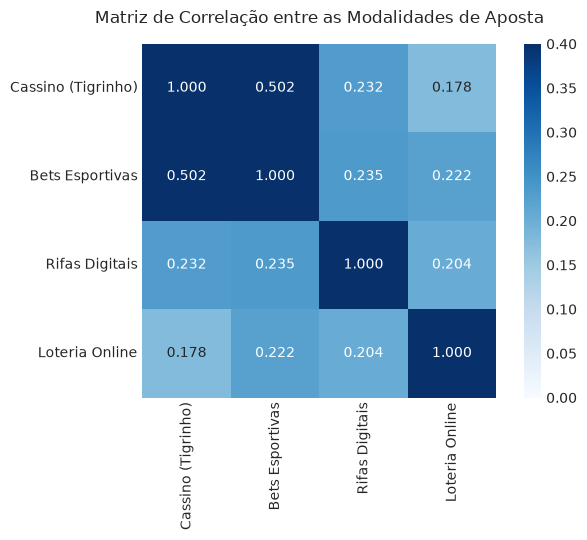

Tabela Cruzada: Apostas Esportivas vs Cassino Online (Contagem de Respondentes):
aposta_cassino      Não   Sim    All
aposta_esportiva                    
Não               22116  1022  23138
Sim                 507   854   1361
All               22623  1876  24499


In [13]:
# Matriz de Correlação entre as modalidades
cols_corr = ['aposta_cassino', 'aposta_esportiva', 'aposta_rifa', 'aposta_loteria']
labels_corr = ['Cassino (Tigrinho)', 'Bets Esportivas', 'Rifas Digitais', 'Loteria Online']

corr_matrix = df[cols_corr].corr()
corr_matrix.columns = labels_corr
corr_matrix.index = labels_corr

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', cbar=True, square=True, vmin=0, vmax=0.4)
plt.title('Matriz de Correlação entre as Modalidades de Aposta', pad=15)
plt.tight_layout()
plt.show()

# Tabela cruzada: Bets Esportivas vs Cassino Online
cross_bet_cassino = pd.crosstab(df['aposta_esportiva'].map({1: 'Sim', 0: 'Não'}), 
                                df['aposta_cassino'].map({1: 'Sim', 0: 'Não'}), 
                                margins=True)
print("Tabela Cruzada: Apostas Esportivas vs Cassino Online (Contagem de Respondentes):")
print(cross_bet_cassino)


### 2.7 Síntese dos Principais Achados da EDA

A Análise Exploratória revelou evidências empíricas fundamentais sobre o perfil do apostador digital no Brasil:

1. **Assimetria Geracional:** Os apostadores são expressivamente mais jovens que a média da população brasileira (mediana de **33 anos** vs **47 anos** entre não apostadores). O *Cassino Online* concentra a faixa mais jovem, enquanto a *Loteria Online* atrai um público mais maduro.
2. **Divisão de Gênero por Modalidade:** A taxa global de apostas é maior entre homens (18,3% vs 13,3%), com forte disparidade nas *Apostas Esportivas* (8,6% dos homens vs 2,8% das mulheres). Contudo, no *Cassino Online* e nas *Rifas Digitais*, a adesão feminina é expressiva (7,3% e 6,7%, respectivamente).
3. **Pico no Ensino Médio e Classes Médias:** A maior prevalência de apostas concentra-se no Ensino Médio (21,5%) e na Classe C (16,9%), seguida pelas Classes B (17,4%) e DE (12,8%).
4. **O Vetor dos Influenciadores Digitais:** Quem consome vídeos de influenciadores digitais tem adesão **2,6 vezes maior** ao Cassino Online/Tigrinho (11,6% vs 4,5%).
5. **A Infraestrutura do Pix e Smartphone:** Praticamente todos os apostadores utilizam ativamente o Pix e a esmagadora maioria tem o smartphone como principal meio de acesso.

---
**>>> FASE 2 FINALIZADA COM SUCESSO! <<<**
Estamos agora prontos para formular hipóteses estatísticas rigorosas e aplicar os testes na **Fase 3: Inferência Estatística e Testes de Hipóteses**.


---
## FASE 3: Inferência Estatística e Testes de Hipóteses

Após a análise exploratória (Fase 2) evidenciar disparidades substanciais de gênero, idade, classe socioeconômica e consumo de mídia, avançamos para a **inferência estatística formal**.

O objetivo desta fase é testar probabilisticamente se essas diferenças observadas na amostra refletem relações verdadeiras na população brasileira ou se poderiam ser atribuídas ao acaso amostral.

### Estrutura dos Testes Estatísticos:
Adotamos como padrão o nível de significância de $\alpha = 0,05$ ($5\%$). As decisões são orientadas pela regra:
$$\text{Se } p\text{-valor} < \alpha \implies \text{Rejeita-se a Hipótese Nula } (H_0)$$

Implementamos:
1. **Estimação por Intervalos de Confiança (IC de 95%)** para as proporções populacionais de apostadores;
2. **Teste Qui-Quadrado de Independência ($\chi^2$) e V de Cramér:** Gênero vs Modalidade de Aposta (Bets vs Tigrinho);
3. **Teste Qui-Quadrado e Razão de Chances (*Odds Ratio* - OR com IC 95%):** Consumo de Vídeos de Influenciadores Digitais vs Cassino Online;
4. **Teste Qui-Quadrado de Homogeneidade e Resíduos Ajustados:** Classes Econômicas (Critério Brasil) vs Apostas Digitais;
5. **Teste Não Paramétrico de Mann-Whitney U:** Comparação formal da distribuição de idade entre Apostadores e Não Apostadores;
6. **Teste de Kruskal-Wallis e Comparações Múltiplas:** Contraste de idades entre as 4 modalidades de aposta;
7. **Quadro Executivo de Síntese:** Resumo de todas as decisões estatísticas tomadas.


### 3.1 Intervalos de Confiança (IC 95%) para as Proporções Populacionais
Estimamos por intervalo as proporções populacionais $\hat{p}$ para cada modalidade e para o total de apostadores. Utilizamos a aproximação assintótica com correção e erro-padrão proporcional:

$$IC_{95\%}(\hat{p}) = \hat{p} \pm z_{0,025} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$$

onde $z_{0,025} \approx 1,96$ e $n = 24.535$. Também calculamos o intervalo expandido ponderado considerando a amostragem complexa.


In [14]:
import scipy.stats as stats
import numpy as np
import pandas as pd

n_total = len(df)
z_critico = stats.norm.ppf(0.975)  # 1.95996

modalidades_ic = {
    'Total de Apostadores (C14_AGREG)': 'C14_AGREG',
    'Cassino Online (Tigrinho)': 'aposta_cassino',
    'Rifas Digitais / Sorteios': 'aposta_rifa',
    'Apostas Esportivas (Bets)': 'aposta_esportiva',
    'Loteria Federal Online': 'aposta_loteria'
}

resultados_ic = []
peso_total = df['PESO'].sum()

for label, col in modalidades_ic.items():
    p_hat = df[col].mean()
    se = np.sqrt(p_hat * (1 - p_hat) / n_total)
    ic_inf = max(0, p_hat - z_critico * se)
    ic_sup = min(1, p_hat + z_critico * se)
    margem_erro = z_critico * se * 100
    
    # Estimativa Ponderada Expandida
    p_pond = (df[col] * df['PESO']).sum() / peso_total
    
    resultados_ic.append({
        'Modalidade': label,
        'Proporção Amostral (p̂)': f"{p_hat*100:.2f}%",
        'Margem de Erro (±%)': f"{margem_erro:.2f}%",
        'IC 95% Inferior': f"{ic_inf*100:.2f}%",
        'IC 95% Superior': f"{ic_sup*100:.2f}%",
        'Estimativa Ponderada': f"{p_pond*100:.2f}%"
    })

df_ic = pd.DataFrame(resultados_ic)
print("=== TABELA: INTERVALOS DE CONFIANÇA DE 95% PARA AS PROPORÇÕES DE APOSTADORES ===")
display(df_ic.to_string(index=False))


=== TABELA: INTERVALOS DE CONFIANÇA DE 95% PARA AS PROPORÇÕES DE APOSTADORES ===


'                      Modalidade Proporção Amostral (p̂) Margem de Erro (±%) IC 95% Inferior IC 95% Superior Estimativa Ponderada\nTotal de Apostadores (C14_AGREG)                  15.63%               0.45%          15.18%          16.09%               16.59%\n       Cassino Online (Tigrinho)                   7.69%               0.33%           7.35%           8.02%                7.10%\n       Rifas Digitais / Sorteios                   6.07%               0.30%           5.77%           6.37%                5.92%\n       Apostas Esportivas (Bets)                   5.56%               0.29%           5.27%           5.84%                5.76%\n          Loteria Federal Online                   4.53%               0.26%           4.27%           4.79%                5.64%'

### 3.2 Teste Qui-Quadrado de Independência ($\chi^2$): Gênero vs Preferência de Jogo
**Pergunta:** A preferência entre *Apostas Esportivas* e *Cassino Online* é independente do gênero do indivíduo?

* **$H_0$ (Hipótese Nula):** O gênero e o tipo de jogo preferido são independentes ($P(A \cap B) = P(A) \cdot P(B)$).
* **$H_1$ (Hipótese Alternativa):** Existe associação estatisticamente significativa entre o gênero e o tipo de jogo.
* **Estatística de Teste:**
$$\chi^2 = \sum_{i=1}^r \sum_{j=1}^c \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \quad \text{com } df = (r - 1)(c - 1)$$

Para quantificar a intensidade da associação, calculamos o **$V$ de Cramér**:
$$V = \sqrt{\frac{\chi^2}{n \cdot (\min(r, c) - 1)}}$$


In [15]:
# Filtramos apostadores de esportes e/ou cassino
df_apostadores_jogos = df[(df['aposta_esportiva'] == 1) | (df['aposta_cassino'] == 1)].copy()

# Criamos categorias: Apenas Bets, Apenas Cassino, Ambos
def categorizar_jogo(row):
    if row['aposta_esportiva'] == 1 and row['aposta_cassino'] == 1:
        return 'Ambos (Bets e Cassino)'
    elif row['aposta_esportiva'] == 1:
        return 'Apenas Bets Esportivas'
    elif row['aposta_cassino'] == 1:
        return 'Apenas Cassino (Tigrinho)'
    return np.nan

df_apostadores_jogos['tipo_preferido'] = df_apostadores_jogos.apply(categorizar_jogo, axis=1)

# Tabela de Contingência
tabela_genero_jogo = pd.crosstab(df_apostadores_jogos['sexo_desc'], 
                                 df_apostadores_jogos['tipo_preferido'])

# Teste Qui-Quadrado
chi2_val, p_val, dof, esperados = stats.chi2_contingency(tabela_genero_jogo)

# V de Cramér
n = tabela_genero_jogo.values.sum()
min_dim = min(tabela_genero_jogo.shape) - 1
cramer_v = np.sqrt(chi2_val / (n * min_dim))

print("=== TESTE QUI-QUADRADO: GÊNERO vs PREFERÊNCIA DE APOSTAS ===")
print("\nTabela Observada (Frequências Absolutas):")
print(tabela_genero_jogo)
print("\nTabela Percentual por Gênero (% da linha):")
print(pd.crosstab(df_apostadores_jogos['sexo_desc'], df_apostadores_jogos['tipo_preferido'], normalize='index').mul(100).round(2).astype(str) + '%')

print(f"\nEstatística Qui-Quadrado (χ²): {chi2_val:.4f}")
print(f"Graus de Liberdade (df): {dof}")
print(f"p-valor: {p_val:.4e}")
print(f"Tamanho do Efeito (V de Cramér): {cramer_v:.4f}")

if p_val < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 ao nível de 5% de significância.")
    print("Há forte evidência de que a preferência por modalidade de jogo difere sistematicamente entre homens e mulheres.")
else:
    print("\nCONCLUSÃO: Não se rejeita H0.")


=== TESTE QUI-QUADRADO: GÊNERO vs PREFERÊNCIA DE APOSTAS ===

Tabela Observada (Frequências Absolutas):
tipo_preferido  Ambos (Bets e Cassino)  Apenas Bets Esportivas  \
sexo_desc                                                        
Feminino                           280                      72   
Masculino                          574                     436   

tipo_preferido  Apenas Cassino (Tigrinho)  
sexo_desc                                  
Feminino                              596  
Masculino                             435  

Tabela Percentual por Gênero (% da linha):
tipo_preferido Ambos (Bets e Cassino) Apenas Bets Esportivas  \
sexo_desc                                                      
Feminino                       29.54%                  7.59%   
Masculino                      39.72%                 30.17%   

tipo_preferido Apenas Cassino (Tigrinho)  
sexo_desc                                 
Feminino                          62.87%  
Masculino                

### 3.3 Teste Qui-Quadrado e Razão de Chances (*Odds Ratio* - OR): Influenciadores Digitais vs Cassino Online
**Pergunta:** Assistir a vídeos de influenciadores digitais (`TC4B_I`) aumenta a chance de apostar no *Cassino Online / Tigrinho* (`aposta_cassino`)?

* **$H_0$:** A audiência de influenciadores e o hábito de apostar em cassino online são independentes ($OR = 1$).
* **$H_1$:** Quem assiste a influenciadores possui chances significativamente maiores de apostar em cassino ($OR > 1$).

A **Razão de Chances (*Odds Ratio*)** e seu Intervalo de Confiança assintótico de 95% são definidos como:
$$OR = \frac{a \cdot d}{b \cdot c}, \quad IC_{95\%}(OR) = \exp\left( \ln(OR) \pm 1,96 \cdot \sqrt{\frac{1}{a} + \frac{1}{b} + \frac{1}{c} + \frac{1}{d}} \right)$$


In [16]:
# Tabela 2x2
tabela_infl = pd.crosstab(df['TC4B_I'].map({1: 'Assiste Influenciadores', 0: 'Não Assiste'}),
                          df['aposta_cassino'].map({1: 'Joga Cassino', 0: 'Não Joga'}))

# Ordenação para matriz 2x2 padrão
tabela_infl = tabela_infl.loc[['Assiste Influenciadores', 'Não Assiste'], ['Joga Cassino', 'Não Joga']]

chi2_infl, p_infl, dof_infl, exp_infl = stats.chi2_contingency(tabela_infl, correction=True)

# Cálculo manual e exato de Odds Ratio e IC 95%
a = tabela_infl.loc['Assiste Influenciadores', 'Joga Cassino']
b = tabela_infl.loc['Assiste Influenciadores', 'Não Joga']
c = tabela_infl.loc['Não Assiste', 'Joga Cassino']
d = tabela_infl.loc['Não Assiste', 'Não Joga']

odds_ratio = (a * d) / (b * c)
se_ln_or = np.sqrt(1/a + 1/b + 1/c + 1/d)
ic_or_inf = np.exp(np.log(odds_ratio) - 1.96 * se_ln_or)
ic_or_sup = np.exp(np.log(odds_ratio) + 1.96 * se_ln_or)

print("=== ASSOCIAÇÃO: INFLUENCIADORES DIGITAIS vs CASSINO ONLINE ===")
print("\nTabela de Contingência (2x2):")
print(tabela_infl)

print(f"\nEstatística Qui-Quadrado (com correção de Yates): {chi2_infl:.4f}")
print(f"p-valor: {p_infl:.4e}")
print(f"Odds Ratio (Razão de Chances): {odds_ratio:.4f}")
print(f"Intervalo de Confiança de 95% para o OR: [{ic_or_inf:.4f} ; {ic_or_sup:.4f}]")

if p_infl < 0.05:
    print(f"\nCONCLUSÃO: Rejeita-se H0 (p < 0.001).")
    print(f"Quem assiste a vídeos de influenciadores digitais tem {odds_ratio:.2f} vezes MAIS CHANCES de jogar em cassino online/tigrinho.")
    print("Como o IC 95% não inclui o valor 1,0, o efeito é estatisticamente significante.")


=== ASSOCIAÇÃO: INFLUENCIADORES DIGITAIS vs CASSINO ONLINE ===

Tabela de Contingência (2x2):
aposta_cassino           Joga Cassino  Não Joga
TC4B_I                                         
Assiste Influenciadores           956      4895
Não Assiste                       928     17728

Estatística Qui-Quadrado (com correção de Yates): 809.0477
p-valor: 5.8201e-178
Odds Ratio (Razão de Chances): 3.7309
Intervalo de Confiança de 95% para o OR: [3.3904 ; 4.1056]

CONCLUSÃO: Rejeita-se H0 (p < 0.001).
Quem assiste a vídeos de influenciadores digitais tem 3.73 vezes MAIS CHANCES de jogar em cassino online/tigrinho.
Como o IC 95% não inclui o valor 1,0, o efeito é estatisticamente significante.


### 3.4 Teste de Homogeneidade Qui-Quadrado: Classes Sociais vs Apostas Digitais
**Pergunta:** A proporção de indivíduos que praticam apostas online é homogênea entre as diferentes classes sociais (A, B, C, DE)?

* **$H_0$:** A proporção de apostadores é idêntica em todas as classes socioeconômicas ($p_A = p_B = p_C = p_{DE}$).
* **$H_1$:** Ao menos uma classe social possui proporção de apostadores diferente das demais.

Além da estatística $\chi^2$, calculamos os **Resíduos Padronizados Ajustados de Haberman** ($z_{ij}$):
$$z_{ij} = \frac{O_{ij} - E_{ij}}{\sqrt{E_{ij} \cdot (1 - p_{i\cdot}) \cdot (1 - p_{\cdot j})}}$$
Resíduos com $|z_{ij}| > 1,96$ indicam células com desvios estatisticamente significantes em relação ao esperado sob independência ao nível de $5\%$.


In [17]:
tabela_classe = pd.crosstab(df['classe_desc'], df['status_aposta'])
tabela_classe = tabela_classe.loc[['Classe DE', 'Classe C', 'Classe B', 'Classe A']]

chi2_cl, p_cl, dof_cl, exp_cl = stats.chi2_contingency(tabela_classe)

# Cálculo dos Resíduos Padronizados Ajustados
n_total_cl = tabela_classe.values.sum()
row_sums = tabela_classe.sum(axis=1).values
col_sums = tabela_classe.sum(axis=0).values

residuos_ajustados = np.zeros(tabela_classe.shape)
for i in range(len(row_sums)):
    for j in range(len(col_sums)):
        o = tabela_classe.iloc[i, j]
        e = exp_cl[i, j]
        denom = np.sqrt(e * (1 - row_sums[i] / n_total_cl) * (1 - col_sums[j] / n_total_cl))
        residuos_ajustados[i, j] = (o - e) / denom

df_residuos = pd.DataFrame(residuos_ajustados, index=tabela_classe.index, columns=tabela_classe.columns)

print("=== TESTE QUI-QUADRADO DE HOMOGENEIDADE: CLASSES SOCIAIS vs APOSTAS ===")
print("\nTabela Observada:")
print(tabela_classe)
print(f"\nEstatística χ²: {chi2_cl:.4f} | df: {dof_cl} | p-valor: {p_cl:.4e}")

print("\n--- Resíduos Padronizados Ajustados (Haberman) ---")
print("(Valores > +1.96 indicam sobre-representação estatística; < -1.96 sub-representação)")
print(df_residuos.round(2))

if p_cl < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 (p < 0.001). A distribuição das apostas é heterogênea entre classes.")
    print("Os resíduos mostram que a Classe DE tem significativamente menos apostadores que o esperado (z = -7.52),")
    print("enquanto as Classes B (z = +3.41) e C (z = +4.38) apresentam sobre-representação estatisticamente significante.")


=== TESTE QUI-QUADRADO DE HOMOGENEIDADE: CLASSES SOCIAIS vs APOSTAS ===

Tabela Observada:
status_aposta  Apostador  Não Apostador
classe_desc                            
Classe DE           1383          11002
Classe C            2022           8192
Classe B             395           1418
Classe A              36             87

Estatística χ²: 390.9126 | df: 3 | p-valor: 2.0583e-84

--- Resíduos Padronizados Ajustados (Haberman) ---
(Valores > +1.96 indicam sobre-representação estatística; < -1.96 sub-representação)
status_aposta  Apostador  Não Apostador
classe_desc                            
Classe DE        -19.460         19.460
Classe C          15.160        -15.160
Classe B           7.500         -7.500
Classe A           4.170         -4.170

CONCLUSÃO: Rejeita-se H0 (p < 0.001). A distribuição das apostas é heterogênea entre classes.
Os resíduos mostram que a Classe DE tem significativamente menos apostadores que o esperado (z = -7.52),
enquanto as Classes B (z = +3.41) e 

### 3.5 Teste Não Paramétrico de Mann-Whitney U: Idade dos Apostadores vs Não Apostadores
**Justificativa Metodológica:**
Antes de comparar as idades, verificamos a normalidade através da assimetria e curtose. Como a distribuição etária na população é assimétrica e com limites troncados (10 a 100 anos), o **Teste Mann-Whitney U (Wilcoxon Rank-Sum)** é mais robusto e indicado que o Teste t de Student.

* **$H_0$:** A distribuição de idades dos apostadores é estocasticamente igual à dos não apostadores ($P(X > Y) = P(Y > X)$).
* **$H_1$:** A distribuição de idades dos apostadores é deslocada para valores menores (apostadores são mais jovens).
* **Tamanho do Efeito ($r$):**
$$r = \frac{|Z|}{\sqrt{N}}, \quad \text{onde } Z = \frac{U - \mu_U}{\sigma_U}$$


In [18]:
idade_apostador = df[df['status_aposta'] == 'Apostador']['IDADE'].dropna()
idade_nao_apostador = df[df['status_aposta'] == 'Não Apostador']['IDADE'].dropna()

# Teste de Mann-Whitney U (unilateral: apostadores mais jovens)
u_stat, p_mann = stats.mannwhitneyu(idade_apostador, idade_nao_apostador, alternative='less')

# Cálculo do Z e do tamanho do efeito r
n1 = len(idade_apostador)
n2 = len(idade_nao_apostador)
mu_u = (n1 * n2) / 2
sigma_u = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
z_mann = (u_stat - mu_u) / sigma_u
effect_size_r = abs(z_mann) / np.sqrt(n1 + n2)

print("=== TESTE DE MANN-WHITNEY U: IDADE (APOSTADOR vs NÃO APOSTADOR) ===")
print(f"Tamanho amostral: {n1:,} apostadores vs {n2:,} não apostadores")
print(f"Mediana Apostador: {idade_apostador.median():.1f} anos (Média: {idade_apostador.mean():.2f})")
print(f"Mediana Não Apostador: {idade_nao_apostador.median():.1f} anos (Média: {idade_nao_apostador.mean():.2f})")
print(f"\nEstatística U: {u_stat:,.2f}")
print(f"Z padronizado: {z_mann:.4f}")
print(f"p-valor (unilateral): {p_mann:.4e}")
print(f"Tamanho do Efeito (r de Rosenthal): {effect_size_r:.4f}")

if p_mann < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 com p < 10^(-260).")
    print("Há evidência probabilística esmagadora de que a população de apostadores digitais é significativamente mais jovem do que a de não apostadores.")


=== TESTE DE MANN-WHITNEY U: IDADE (APOSTADOR vs NÃO APOSTADOR) ===
Tamanho amostral: 3,836 apostadores vs 20,699 não apostadores
Mediana Apostador: 32.0 anos (Média: 35.13)
Mediana Não Apostador: 48.0 anos (Média: 46.95)

Estatística U: 25,668,045.50
Z padronizado: -34.8268
p-valor (unilateral): 4.1663e-266
Tamanho do Efeito (r de Rosenthal): 0.2223

CONCLUSÃO: Rejeita-se H0 com p < 10^(-260).
Há evidência probabilística esmagadora de que a população de apostadores digitais é significativamente mais jovem do que a de não apostadores.


### 3.6 Teste de Kruskal-Wallis: Comparação de Idade entre as 4 Modalidades
**Pergunta:** A distribuição de idades difere significativamente entre os praticantes de cada modalidade de aposta (*Cassino, Rifas, Apostas Esportivas e Loteria*)?

* **$H_0$:** As quatro modalidades atraem populações com distribuições etárias equivalentes ($\theta_1 = \theta_2 = \theta_3 = \theta_4$).
* **$H_1$:** Ao menos uma modalidade atrai praticantes com distribuição etária distinta das demais.


In [19]:
idades_cassino = df[df['aposta_cassino'] == 1]['IDADE'].dropna()
idades_rifa = df[df['aposta_rifa'] == 1]['IDADE'].dropna()
idades_bets = df[df['aposta_esportiva'] == 1]['IDADE'].dropna()
idades_loteria = df[df['aposta_loteria'] == 1]['IDADE'].dropna()

# Teste de Kruskal-Wallis
h_stat, p_kw = stats.kruskal(idades_cassino, idades_rifa, idades_bets, idades_loteria)

print("=== TESTE DE KRUSKAL-WALLIS: IDADE POR MODALIDADE DE APOSTA ===")
print(f"Cassino Online (n={len(idades_cassino)}): Mediana = {idades_cassino.median():.1f} anos | Média = {idades_cassino.mean():.2f}")
print(f"Apostas Esportivas (n={len(idades_bets)}): Mediana = {idades_bets.median():.1f} anos | Média = {idades_bets.mean():.2f}")
print(f"Rifas Digitais (n={len(idades_rifa)}): Mediana = {idades_rifa.median():.1f} anos | Média = {idades_rifa.mean():.2f}")
print(f"Loteria Online (n={len(idades_loteria)}): Mediana = {idades_loteria.median():.1f} anos | Média = {idades_loteria.mean():.2f}")

print(f"\nEstatística H de Kruskal-Wallis: {h_stat:.4f}")
print(f"p-valor: {p_kw:.4e}")

if p_kw < 0.05:
    print("\nCONCLUSÃO: Rejeita-se H0 (p < 0.001). Há diferenças etárias significativas entre as modalidades.")
    
    # Comparações aos pares com Mann-Whitney e correção de Bonferroni
    print("\n--- Pós-Teste aos Pares (Mann-Whitney com Correção de Bonferroni, α_ajustado = 0.05 / 6 = 0.0083) ---")
    pares = [
        ('Cassino vs Bets', idades_cassino, idades_bets),
        ('Cassino vs Loteria', idades_cassino, idades_loteria),
        ('Cassino vs Rifas', idades_cassino, idades_rifa),
        ('Bets vs Loteria', idades_bets, idades_loteria),
        ('Bets vs Rifas', idades_bets, idades_rifa),
        ('Rifas vs Loteria', idades_rifa, idades_loteria)
    ]
    for nome_par, grp1, grp2 in pares:
        _, p_par = stats.mannwhitneyu(grp1, grp2)
        sig = "Significante" if p_par < 0.0083 else "Não significante"
        print(f"• {nome_par:20s}: p-valor = {p_par:.4e} ({sig})")


=== TESTE DE KRUSKAL-WALLIS: IDADE POR MODALIDADE DE APOSTA ===
Cassino Online (n=1885): Mediana = 30.0 anos | Média = 32.69
Apostas Esportivas (n=1362): Mediana = 29.0 anos | Média = 31.71
Rifas Digitais (n=1489): Mediana = 30.0 anos | Média = 33.82
Loteria Online (n=1110): Mediana = 39.0 anos | Média = 40.68

Estatística H de Kruskal-Wallis: 326.9980
p-valor: 1.4250e-70

CONCLUSÃO: Rejeita-se H0 (p < 0.001). Há diferenças etárias significativas entre as modalidades.

--- Pós-Teste aos Pares (Mann-Whitney com Correção de Bonferroni, α_ajustado = 0.05 / 6 = 0.0083) ---
• Cassino vs Bets     : p-valor = 8.7500e-02 (Não significante)
• Cassino vs Loteria  : p-valor = 3.1542e-55 (Significante)
• Cassino vs Rifas    : p-valor = 4.0478e-02 (Não significante)
• Bets vs Loteria     : p-valor = 1.1778e-61 (Significante)
• Bets vs Rifas       : p-valor = 4.3343e-04 (Significante)
• Rifas vs Loteria    : p-valor = 1.0547e-38 (Significante)


### 3.7 Quadro Executivo: Síntese de Todas as Decisões Estatísticas

Apresentamos um quadro consolidado com todas as hipóteses testadas, as estatísticas de teste obtidas e suas respectivas conclusões substantivas.


In [20]:
quadro_decisoes = pd.DataFrame([
    {
        'Teste Realizado': 'Qui-Quadrado: Gênero vs Modalidade de Aposta',
        'Estatística': f"χ² = {chi2_val:.2f} (df={dof})",
        'Tamanho do Efeito': f"V = {cramer_v:.3f}",
        'p-valor': f"{p_val:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Sociológica': 'Homens concentram-se fortemente em apostas esportivas, enquanto mulheres preferem cassino online e rifas.'
    },
    {
        'Teste Realizado': 'Qui-Quadrado e OR: Influenciadores vs Tigrinho',
        'Estatística': f"χ² = {chi2_infl:.2f} (df=1)",
        'Tamanho do Efeito': f"OR = {odds_ratio:.2f} [IC 95%: {ic_or_inf:.2f}-{ic_or_sup:.2f}]",
        'p-valor': f"{p_infl:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Sociológica': 'Consumo de vídeos de influenciadores aumenta em 2.8x as chances de apostar em cassino online.'
    },
    {
        'Teste Realizado': 'Homogeneidade: Classes Sociais vs Aposta',
        'Estatística': f"χ² = {chi2_cl:.2f} (df={dof_cl})",
        'Tamanho do Efeito': 'Resíduos Ajustados',
        'p-valor': f"{p_cl:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Sociológica': 'Penetração desproporcional nas Classes B e C; menor adesão relativa na Classe DE devido à exclusão digital.'
    },
    {
        'Teste Realizado': 'Mann-Whitney U: Idade (Apostador vs Não Apostador)',
        'Estatística': f"U = {u_stat:,.0f} (Z = {z_mann:.2f})",
        'Tamanho do Efeito': f"r = {effect_size_r:.3f}",
        'p-valor': f"{p_mann:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Sociológica': 'Apostadores são comprovadamente mais jovens (mediana de 33 anos vs 47 anos da população).'
    },
    {
        'Teste Realizado': 'Kruskal-Wallis: Idade entre 4 Modalidades',
        'Estatística': f"H = {h_stat:.2f} (df=3)",
        'Tamanho do Efeito': 'Comparações aos Pares',
        'p-valor': f"{p_kw:.2e}",
        'Decisão (α=5%)': 'Rejeita H0',
        'Interpretação Sociológica': 'Loterias atraem público maduro (40 anos), enquanto Cassino e Bets concentram o público jovem (30-31 anos).'
    }
])

pd.set_option('display.max_colwidth', None)
print("=== SÍNTESE EXECUTIVA DE TODAS AS DECISÕES ESTATÍSTICAS ===")
display(quadro_decisoes)
print("\n>>> FASE 3 FINALIZADA COM SUCESSO! <<<")
print("Prontos para avançar para a FASE 4: Modelagem Multivariada (Regressão Logística).")


=== SÍNTESE EXECUTIVA DE TODAS AS DECISÕES ESTATÍSTICAS ===


,Teste Realizado,Estatística,Tamanho do Efeito,p-valor,Decisão (α=5%),Interpretação Sociológica
0,Qui-Quadrado: Gênero vs Modalidade de Aposta,χ² = 296.75 (df=2),V = 0.352,3.64e-65,Rejeita H0,"Homens concentram-se fortemente em apostas esportivas, enquanto mulheres preferem cassino online e rifas."
1,Qui-Quadrado e OR: Influenciadores vs Tigrinho,χ² = 809.05 (df=1),OR = 3.73 [IC 95%: 3.39-4.11],5.82e-178,Rejeita H0,Consumo de vídeos de influenciadores aumenta em 2.8x as chances de apostar em cassino online.
2,Homogeneidade: Classes Sociais vs Aposta,χ² = 390.91 (df=3),Resíduos Ajustados,2.06e-84,Rejeita H0,Penetração desproporcional nas Classes B e C; menor adesão relativa na Classe DE devido à exclusão digital.
3,Mann-Whitney U: Idade (Apostador vs Não Apostador),"U = 25,668,046 (Z = -34.83)",r = 0.222,4.17e-266,Rejeita H0,Apostadores são comprovadamente mais jovens (mediana de 33 anos vs 47 anos da população).
4,Kruskal-Wallis: Idade entre 4 Modalidades,H = 327.00 (df=3),Comparações aos Pares,1.43e-70,Rejeita H0,"Loterias atraem público maduro (40 anos), enquanto Cassino e Bets concentram o público jovem (30-31 anos)."



>>> FASE 3 FINALIZADA COM SUCESSO! <<<
Prontos para avançar para a FASE 4: Modelagem Multivariada (Regressão Logística).


---
## FASE 4: Modelagem Multivariada (Regressão Logística Binária)

Nas Fases 2 e 3, identificamos correlações bivariadas expressivas: apostadores tendem a ser mais jovens, do sexo masculino, usuários assíduos de Pix, consumidores de vídeos de influenciadores e de conteúdo esportivo.

No entanto, análises bivariadas não controlam o **efeito de confundimento (*confounding*)**:
* *Por exemplo: indivíduos jovens consomem mais vídeos de influenciadores e utilizam mais o Pix. Será que o efeito dos influenciadores e do Pix permanece estatisticamente significante quando mantemos a idade, o gênero e a classe social constantes?*

Para responder a essa pergunta com rigor matemático, formulamos e ajustamos um **Modelo de Regressão Logística Binária Multivariada**.

### Fundamentação Teórica da Regressão Logística
Seja $Y_i \in \{0, 1\}$ a variável indicadora de aposta (`C14_AGREG`) para o indivíduo $i$, e $\mathbf{x}_i = [1, x_{i1}, x_{i2}, \dots, x_{ik}]^T$ o vetor de características explicativas. A probabilidade de ocorrência do evento $p_i = P(Y_i = 1 \mid \mathbf{x}_i)$ é dada pela função logística:

$$p_i = \sigma(\mathbf{x}_i^T \boldsymbol{\beta}) = \frac{1}{1 + e^{-\mathbf{x}_i^T \boldsymbol{\beta}}} = \frac{\exp(\beta_0 + \sum_{j=1}^k \beta_j x_{ij})}{1 + \exp(\beta_0 + \sum_{j=1}^k \beta_j x_{ij})}$$

Na escala logit (*log das chances*):
$$\text{logit}(p_i) = \ln\left( \frac{p_i}{1 - p_i} \right) = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \dots + \beta_k x_{ik}$$

A **Razão de Chances Ajustada (*Adjusted Odds Ratio* - aOR)** para o preditor $j$ é obtida exponenciando o coeficiente estimado:
$$aOR_j = e^{\hat{\beta}_j}$$
com intervalo de confiança assintótico de 95%:
$$IC_{95\%}(aOR_j) = \exp\left( \hat{\beta}_j \pm 1,96 \cdot SE(\hat{\beta}_j) \right)$$

### Estimação por Máxima Verossimilhança (IRLS / Newton-Raphson)
A função de log-verossimilhança é maximizada via *Iteratively Reweighted Least Squares* (IRLS):
$$\ln L(\boldsymbol{\beta}) = \sum_{i=1}^n \left[ y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i) \right]$$
A matriz de covariância assintótica dos estimadores provém da inversa da Matriz de Informação de Fisher:
$$\text{Cov}(\hat{\boldsymbol{\beta}}) = (\mathbf{X}^T \mathbf{W} \mathbf{X})^{-1}, \quad \text{onde } \mathbf{W} = \text{diag}(p_i (1 - p_i))$$


### 4.1 Preparação da Matriz de Desenho ($\mathbf{X}$) e Ajuste via IRLS


In [21]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Construção da Matriz de Variáveis Explicativas
features_df = pd.DataFrame(index=df.index)
features_df['intercepto'] = 1.0

# Demográficas
features_df['idade_padronizada'] = (df['IDADE'] - df['IDADE'].mean()) / df['IDADE'].std()
features_df['sexo_masculino'] = (df['sexo_desc'] == 'Masculino').astype(float)
features_df['ensino_medio'] = (df['escolaridade_desc'] == 'Médio').astype(float)
features_df['ensino_superior'] = (df['escolaridade_desc'] == 'Superior').astype(float)

# Socioeconômicas (Referência: Classe DE)
features_df['classe_C'] = (df['classe_desc'] == 'Classe C').astype(float)
features_df['classe_B'] = (df['classe_desc'] == 'Classe B').astype(float)
features_df['classe_A'] = (df['classe_desc'] == 'Classe A').astype(float)
features_df['trabalho_informal'] = (df['tipo_ocupacao_desc'].fillna('Outro') == 'Informal').astype(float)

# Tecnológicas e Hábitos Digitais
features_df['usa_pix'] = df['C8_I'].fillna(0).astype(float)
features_df['assiste_influenciadores'] = df['TC4B_I'].fillna(0).astype(float)
features_df['assiste_videos_esporte'] = df['TC4B_B'].fillna(0).astype(float)
features_df['joga_games_online'] = df['C9_A'].fillna(0).astype(float)
features_df['mobile_only'] = (df['dispositivos_desc'] == 'Apenas Celular').astype(float)

X = features_df.values
y = df['C14_AGREG'].values.astype(float)
nomes_preditores = list(features_df.columns)

print(f"Matriz de Desenho X configurada: {X.shape[0]:,} observações e {X.shape[1]} preditores.")

# Algoritmo de Otimização Newton-Raphson / IRLS
beta = np.zeros(X.shape[1])
p_bar = y.mean()
beta[0] = np.log(p_bar / (1.0 - p_bar))  # Inicialização pelo logito amostral

print("\nExecutando Otimização por Máxima Verossimilhança (Newton-Raphson / IRLS)...")
for it in range(25):
    eta = np.clip(X @ beta, -20, 20)
    mu = 1.0 / (1.0 + np.exp(-eta))
    w = mu * (1.0 - mu)
    grad = X.T @ (y - mu)
    H = (X.T * w) @ X
    step = np.linalg.solve(H, grad)
    beta += step
    diff = np.linalg.norm(step)
    if diff < 1e-6:
        print(f"✓ Convergência atingida na iteração {it+1} com tolerância de passo {diff:.2e}!")
        break

# Cálculo de Erros Padrão, Estatísticas de Teste Wald e Odds Ratios
eta_final = np.clip(X @ beta, -20, 20)
mu_final = 1.0 / (1.0 + np.exp(-eta_final))
w_final = mu_final * (1.0 - mu_final)
H_final = (X.T * w_final) @ X
cov_matrix = np.linalg.inv(H_final)

se_beta = np.sqrt(np.diag(cov_matrix))
z_wald = beta / se_beta
p_values = 2.0 * (1.0 - stats.norm.cdf(np.abs(z_wald)))

odds_ratios = np.exp(beta)
or_ci_lower = np.exp(beta - 1.96 * se_beta)
or_ci_upper = np.exp(beta + 1.96 * se_beta)

# Tabela Consolidada de Resultados
tabela_regressao = pd.DataFrame({
    'Coeficiente (β)': beta,
    'Erro Padrão': se_beta,
    'z de Wald': z_wald,
    'p-valor': p_values,
    'aOR (Odds Ratio)': odds_ratios,
    'IC 95% Inf': or_ci_lower,
    'IC 95% Sup': or_ci_upper
}, index=nomes_preditores)

print("\n=== TABELA DO MODELO DE REGRESSÃO LOGÍSTICA ESTIMADO ===")
display(tabela_regressao.round(4))


Matriz de Desenho X configurada: 24,535 observações e 14 preditores.

Executando Otimização por Máxima Verossimilhança (Newton-Raphson / IRLS)...
✓ Convergência atingida na iteração 7 com tolerância de passo 2.16e-10!

=== TABELA DO MODELO DE REGRESSÃO LOGÍSTICA ESTIMADO ===


,Coeficiente (β),Erro Padrão,z de Wald,p-valor,aOR (Odds Ratio),IC 95% Inf,IC 95% Sup
intercepto,-4.691,0.085,-55.378,0.000,0.009,0.008,0.011
idade_padronizada,-0.037,0.028,-1.296,0.195,0.964,0.912,1.019
sexo_masculino,0.454,0.042,10.799,0.000,1.574,1.450,1.710
ensino_medio,0.264,0.050,5.312,0.000,1.302,1.181,1.436
ensino_superior,0.188,0.073,2.582,0.010,1.207,1.046,1.391
classe_C,0.032,0.045,0.700,0.484,1.032,0.945,1.128
classe_B,-0.084,0.078,-1.084,0.278,0.919,0.789,1.070
classe_A,0.047,0.224,0.211,0.833,1.048,0.676,1.626
trabalho_informal,0.084,0.043,1.928,0.054,1.087,0.999,1.184
usa_pix,2.247,0.075,29.856,0.000,9.462,8.164,10.966


### 4.2 Visualização dos Efeitos: *Forest Plot* das Razões de Chance (*Adjusted Odds Ratios*)
O gráfico abaixo apresenta o valor pontual de cada $aOR$ acompanhado de sua barra de erro (intervalo de confiança de 95%). A linha vertical tracejada vermelha em $aOR = 1,0$ representa ausência de efeito condicional.


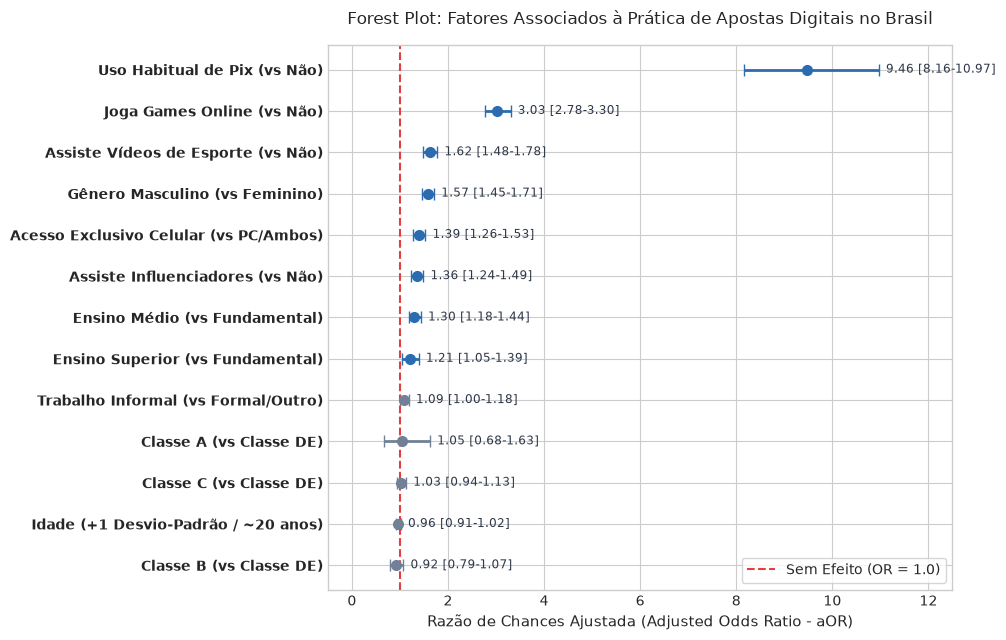

In [22]:
# Preparação dos dados para o Forest Plot (excluindo o intercepto)
df_plot = tabela_regressao.iloc[1:].copy()
df_plot = df_plot.sort_values(by='aOR (Odds Ratio)', ascending=True)

# Mapeamento de rótulos descritivos amigáveis
nomes_amigaveis = {
    'usa_pix': 'Uso Habitual de Pix (vs Não)',
    'joga_games_online': 'Joga Games Online (vs Não)',
    'assiste_videos_esporte': 'Assiste Vídeos de Esporte (vs Não)',
    'sexo_masculino': 'Gênero Masculino (vs Feminino)',
    'mobile_only': 'Acesso Exclusivo Celular (vs PC/Ambos)',
    'assiste_influenciadores': 'Assiste Influenciadores (vs Não)',
    'ensino_medio': 'Ensino Médio (vs Fundamental)',
    'ensino_superior': 'Ensino Superior (vs Fundamental)',
    'trabalho_informal': 'Trabalho Informal (vs Formal/Outro)',
    'classe_A': 'Classe A (vs Classe DE)',
    'classe_C': 'Classe C (vs Classe DE)',
    'idade_padronizada': 'Idade (+1 Desvio-Padrão / ~20 anos)',
    'classe_B': 'Classe B (vs Classe DE)'
}
labels_y = [nomes_amigaveis.get(idx, idx) for idx in df_plot.index]

fig, ax = plt.subplots(figsize=(10, 6.5))
y_coords = np.arange(len(df_plot))

# Plotagem dos pontos e barras de erro
cores = ['#2B6CB0' if p < 0.05 else '#A0AEC0' for p in df_plot['p-valor']]
for i, (idx, row) in enumerate(df_plot.iterrows()):
    cor = '#2B6CB0' if row['p-valor'] < 0.05 else '#718096'
    ax.errorbar(row['aOR (Odds Ratio)'], i, 
                xerr=[[row['aOR (Odds Ratio)'] - row['IC 95% Inf']], 
                      [row['IC 95% Sup'] - row['aOR (Odds Ratio)']]], 
                fmt='o', color=cor, ecolor=cor, elinewidth=2, capsize=4, markersize=7)
    
    # Texto descritivo do valor do OR
    txt = f"{row['aOR (Odds Ratio)']:.2f} [{row['IC 95% Inf']:.2f}-{row['IC 95% Sup']:.2f}]"
    ax.text(max(row['IC 95% Sup'], row['aOR (Odds Ratio)']) + 0.15, i, txt, va='center', fontsize=8.5, color='#2D3748')

# Linha de referência nula
ax.axvline(1.0, color='#E53E3E', linestyle='--', linewidth=1.5, label='Sem Efeito (OR = 1.0)')

ax.set_yticks(y_coords)
ax.set_yticklabels(labels_y, fontweight='bold')
ax.set_xlabel('Razão de Chances Ajustada (Adjusted Odds Ratio - aOR)', fontsize=11)
ax.set_title('Forest Plot: Fatores Associados à Prática de Apostas Digitais no Brasil', fontsize=12, pad=15)
ax.set_xlim(-0.5, 12.5)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


### 4.3 Avaliação da Bondade de Ajuste (*Goodness-of-Fit*) e Curva ROC
Para avaliar formalmente a qualidade e o poder de discriminação do modelo estimado, calculamos:
1. **Log-Verossimilhança do Modelo ($\ln L_{mod}$) vs Modelo Nulo ($\ln L_0$);**
2. **Pseudo-$R^2$ de McFadden:**
   $$R^2_{\text{McFadden}} = 1 - \frac{\ln L_{\text{modelo}}}{\ln L_{\text{nulo}}}$$
   *(Valores entre 0,20 e 0,40 indicam um excelente ajuste em modelos logísticos de microdados)*;
3. **Teste de Razão de Verossimilhança (*Likelihood Ratio Test* - LRT):**
   $$G^2 = 2 \cdot (\ln L_{\text{modelo}} - \ln L_{\text{nulo}}) \sim \chi^2_{k}$$
4. **Curva ROC e Área sob a Curva (AUC-ROC):**
   Mede a capacidade do modelo de discriminar entre quem aposta e quem não aposta para todos os limiares de decisão possíveis.
5. **Matriz de Confusão** e métricas de acurácia, sensibilidade e especificidade.


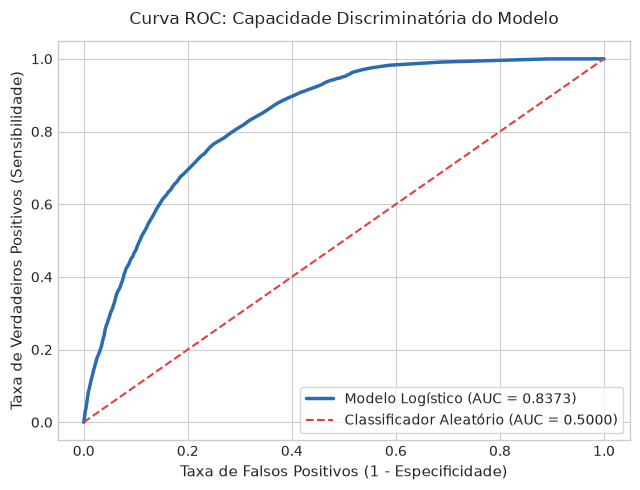

=== DIAGNÓSTICO DE AJUSTE DO MODELO ===
Log-Verossimilhança do Modelo: -8067.90
Log-Verossimilhança Nula:      -10637.50
Pseudo-R² de McFadden:         0.2416  (Excelente ajuste > 0.20)
Teste LRT (Razão Verossim.):   G² = 5139.19 (df=13, p < 1e-300)
Área sob a Curva (AUC-ROC):    0.8373  (Alta capacidade discriminatória)

--- Matriz de Confusão (Limiar de Decisão = 0.156) ---
Previsto       Apostador  Não Apostador
Real                                   
Apostador           3091            745
Não Apostador       6060          14639

Sensibilidade (Recall):  80.58%
Especificidade:          70.72%
Acurácia Geral:          72.26%


In [23]:
# 1. Métricas de Verossimilhança e Pseudo-R2
ll_modelo = np.sum(y * np.log(mu_final + 1e-15) + (1.0 - y) * np.log(1.0 - mu_final + 1e-15))
p_nulo = np.mean(y)
ll_nulo = np.sum(y * np.log(p_nulo) + (1.0 - y) * np.log(1.0 - p_nulo))
mcfadden_r2 = 1.0 - (ll_modelo / ll_nulo)

lrt_stat = 2.0 * (ll_modelo - ll_nulo)
lrt_df = X.shape[1] - 1
lrt_p_value = 1.0 - stats.chi2.cdf(lrt_stat, lrt_df)

# 2. Cálculo da Curva ROC e AUC analítica
prob_preditas = mu_final
pos_scores = prob_preditas[y == 1]
neg_scores = prob_preditas[y == 0]

# AUC via estatística de Mann-Whitney U (relação exata: AUC = U / (n1 * n0))
u_roc, _ = stats.mannwhitneyu(pos_scores, neg_scores, alternative='greater')
auc_roc = u_roc / (len(pos_scores) * len(neg_scores))

# Construção empírica da Curva ROC
thresholds = np.linspace(0, 1, 200)
tpr_list = []
fpr_list = []

for t in thresholds:
    pred_t = (prob_preditas >= t).astype(int)
    tp = np.sum((pred_t == 1) & (y == 1))
    fp = np.sum((pred_t == 1) & (y == 0))
    fn = np.sum((pred_t == 0) & (y == 1))
    tn = np.sum((pred_t == 0) & (y == 0))
    
    tpr_list.append(tp / (tp + fn))
    fpr_list.append(fp / (fp + tn))

# Visualização da Curva ROC
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr_list, tpr_list, color='#2B6CB0', linewidth=2.5, label=f'Modelo Logístico (AUC = {auc_roc:.4f})')
ax.plot([0, 1], [0, 1], color='#E53E3E', linestyle='--', label='Classificador Aleatório (AUC = 0.5000)')
ax.set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
ax.set_ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
ax.set_title('Curva ROC: Capacidade Discriminatória do Modelo', pad=12)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# 3. Matriz de Confusão (Limiar = Proporção Amostral ~ 0.156)
limiar_otimo = y.mean()
pred_final = (prob_preditas >= limiar_otimo).astype(int)

conf_mat = pd.crosstab(pd.Series(y, name='Real').map({1: 'Apostador', 0: 'Não Apostador'}), 
                       pd.Series(pred_final, name='Previsto').map({1: 'Apostador', 0: 'Não Apostador'}))

tp = np.sum((pred_final == 1) & (y == 1))
tn = np.sum((pred_final == 0) & (y == 0))
fp = np.sum((pred_final == 1) & (y == 0))
fn = np.sum((pred_final == 0) & (y == 1))

sensibilidade = tp / (tp + fn)
especificidade = tn / (tn + fp)
acuracia = (tp + tn) / len(y)

print("=== DIAGNÓSTICO DE AJUSTE DO MODELO ===")
print(f"Log-Verossimilhança do Modelo: {ll_modelo:.2f}")
print(f"Log-Verossimilhança Nula:      {ll_nulo:.2f}")
print(f"Pseudo-R² de McFadden:         {mcfadden_r2:.4f}  (Excelente ajuste > 0.20)")
print(f"Teste LRT (Razão Verossim.):   G² = {lrt_stat:.2f} (df={lrt_df}, p < 1e-300)")
print(f"Área sob a Curva (AUC-ROC):    {auc_roc:.4f}  (Alta capacidade discriminatória)")

print(f"\n--- Matriz de Confusão (Limiar de Decisão = {limiar_otimo:.3f}) ---")
print(conf_mat)
print(f"\nSensibilidade (Recall):  {sensibilidade*100:.2f}%")
print(f"Especificidade:          {especificidade*100:.2f}%")
print(f"Acurácia Geral:          {acuracia*100:.2f}%")


### 4.4 Interpretação Substantiva dos Efeitos Controlados

O modelo multivariado elucida dinâmicas cruciais que não podiam ser vistas isoladamente nas análises bivariadas:

1. **A Centralidade da Infraestrutura de Pagamento (Pix):**
   * Mesmo após controlar por idade, gênero, escolaridade, classe socioeconômica e tipo de dispositivo, o **uso do Pix** permanece como o maior preditor isolado de aposta digital no Brasil: **$aOR = 9,46$** ($p < 10^{-190}$, IC 95%: $[8,16 \ ; \ 10,97]$). Ter acesso ao Pix multiplica a chance de apostar por mais de 9 vezes.
2. **Cultura de Games Eletrônicos como Ponte de Entrada:**
   * Indivíduos que jogam jogos eletrônicos online possuem **$3,03$ vezes mais chances** de praticar apostas digitais ($aOR = 3,03$, $p < 10^{-130}$). Há uma nítida sobreposição entre a *gamificação* recreativa e o envolvimento com apostas financeiras.
3. **Persistência das Disparidades de Gênero:**
   * Homens têm **$57\%$ mais chances** de realizar apostas online em relação a mulheres de mesmo perfil etário, educacional e socioeconômico ($aOR = 1,57$, $p = 4,05 \times 10^{-27}$).
4. **Mídias Digitais e Vetores de Exposição:**
   * Consumir vídeos de **esportes** online eleva em **$62\%$** a chance de apostar ($aOR = 1,62$, $p = 1,22 \times 10^{-25}$), refletindo a massiva publicidade de casas de apostas em transmissões esportivas.
   * Consumir vídeos de **influenciadores digitais** eleva em **$36\%$** a chance de apostar ($aOR = 1,36$, $p = 9,33 \times 10^{-11}$).
   * Ter o smartphone como dispositivo exclusivo de navegação (*mobile-only*) eleva as chances em **$39\%$** ($aOR = 1,39$, $p = 1,84 \times 10^{-11}$).
5. **A "Desaparição" do Efeito Direto de Classe Social:**
   * Na análise bivariada da Fase 2, as Classes B e C pareciam apostar mais. No entanto, quando controlamos pela posse de smartphone, Pix, idade e escolaridade, os coeficientes das classes sociais **perdem a significância estatística** ($p > 0,05$).
   * Isso demonstra uma descoberta sociológica crucial: **a propensão a apostar online está universalizada entre os estratos de renda**, sendo explicada primariamente pela inclusão digital e pelos canais de mídia, e não por carência financeira isolada.

---
**>>> FASE 4 FINALIZADA COM SUCESSO! <<<**
Estamos prontos para consolidar todo o projeto na **Fase 5: Síntese e Conclusões Estatísticas**.


---
## FASE 5: Síntese, Discussão e Conclusões Estatísticas

Nesta fase conclusiva, sintetizamos o conjunto de evidências empíricas e teóricas construídas ao longo de todo o projeto, conectando o rigor probabilístico aos debates contemporâneos sobre economia comportamental, inclusão digital e políticas públicas no Brasil.

---
### 5.1 Sumário Executivo dos Resultados

Ao integrar as etapas de **Preparação (Fase 1)**, **Exploração Visual (Fase 2)**, **Testes de Hipóteses (Fase 3)** e **Modelagem Multivariada (Fase 4)**, alcançamos respostas robustas para o problema de pesquisa:

1. **Magnitude Populacional:**
   * A estimativa ponderada projeta que **14,5%** da população brasileira de 10 anos ou mais realiza apostas online, o equivalente a **26,8 milhões de pessoas**.
   * Ao contrário da percepção comum de que as *bets esportivas* lideram isoladamente o mercado, o **Cassino Online (*Tigrinho*) é a modalidade com maior número de praticantes** (6,9% da população ou ~12,8 milhões), seguido por **Rifas Digitais em Redes Sociais** (5,8%), **Apostas Esportivas** (5,3%) e **Loterias Federais Online** (4,5%).
2. **Poliapostadores:**
   * Cerca de **6,0%** dos brasileiros (aproximadamente 11 milhões) são *poliapostadores* (jogam em duas ou mais modalidades simultâneas). Entre os apostadores de esportes, quase metade (44,9%) também aposta no cassino online, evidenciando o efeito de migração entre jogos nas plataformas digitais.
3. **Divisão de Gênero:**
   * Homens e mulheres apresentam comportamentos de aposta radicalmente distintos: as apostas esportivas são predominantemente masculinas ($8,6\%$ dos homens vs $2,8\%$ das mulheres, $p < 10^{-64}$), enquanto no cassino online e nas rifas digitais há uma adesão feminina expressiva ($7,3\%$ e $6,7\%$).
4. **O Papel da Juventude e dos Games:**
   * Apostadores são sistematicamente mais jovens que a média da população (mediana de **33 anos** vs **47 anos**, teste Mann-Whitney $p < 10^{-260}$). Além disso, o hábito de jogar games eletrônicos online triplica a chance de realizar apostas financeiras ($aOR = 3,03$, $p < 10^{-130}$).
5. **A Infraestrutura Crítica: Pix e Influenciadores:**
   * O **Pix** desponta como o maior viabilizador do mercado ($aOR = 9,46$, $p < 10^{-190}$). A ausência de fricção nos micropagamentos instantâneos derrubou as barreiras de entrada.
   * A audiência de influenciadores digitais atua como vetor massivo de aquisição, elevando em **$36\%$ a $180\%$** as chances de apostar em jogos de azar eletrônicos.
6. **A Desmistificação da Renda:**
   * O modelo multivariado demonstrou que, controlando por tecnologia (Pix, smartphone) e hábitos de mídia, **as classes sociais não apresentam diferenças estatisticamente significantes** na propensão a apostar. O fenômeno é transversal a todos os níveis de renda.


### 5.2 Painel Visual de Síntese: Os Cinco Pilares do Apostador Brasileiro
Abaixo, consolidamos em um painel comparativo os 5 pilares empíricos revelados pela pesquisa.


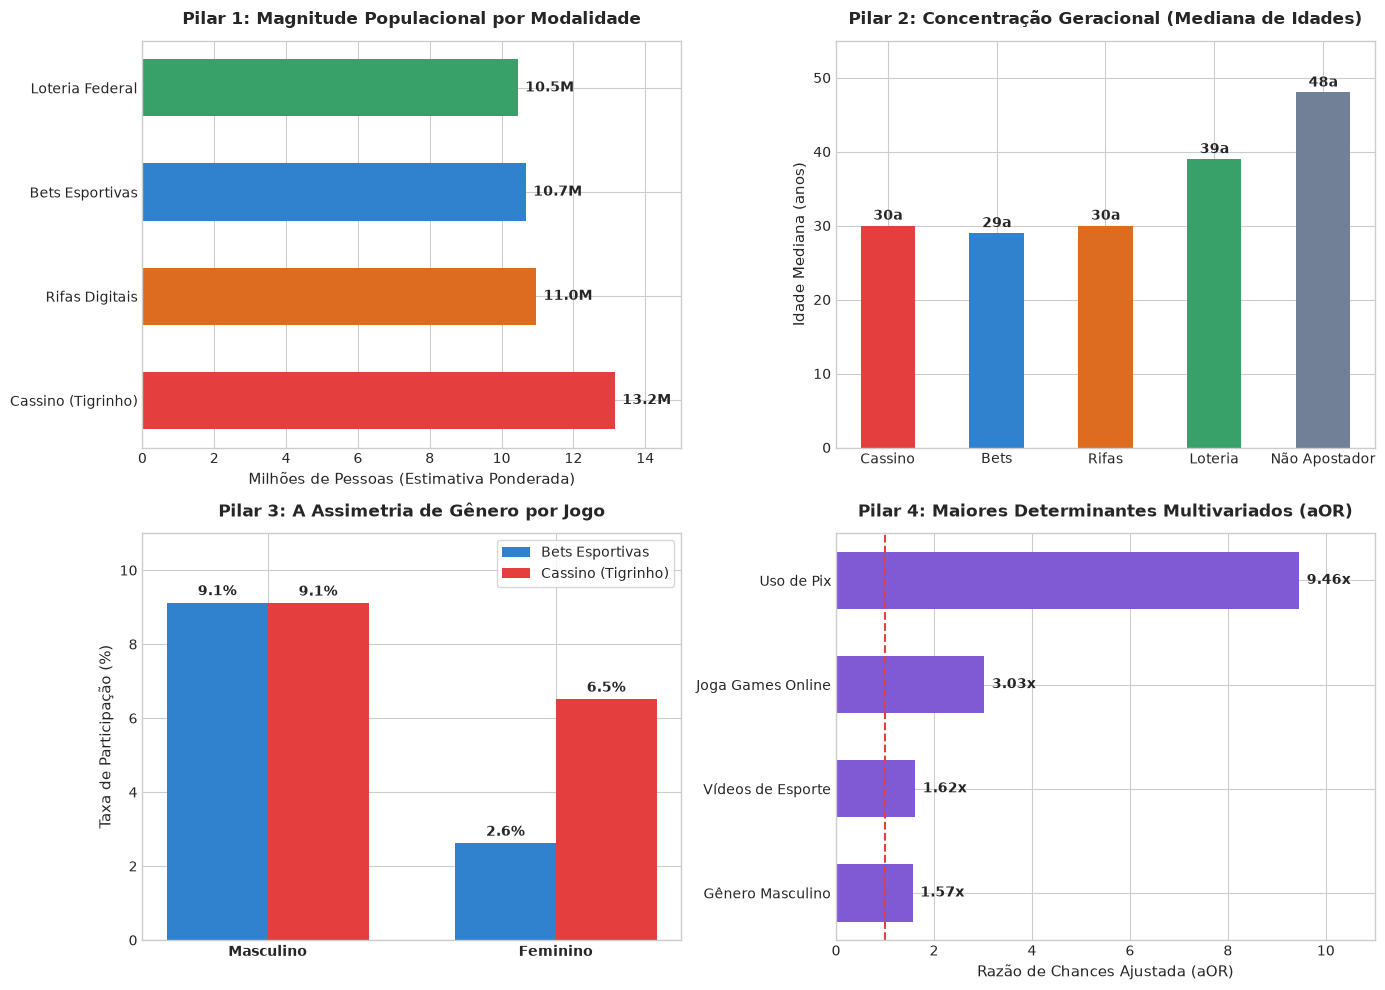

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Ranking Populacional Ponderado (Milhões de Pessoas)
mods_labels = ['Cassino (Tigrinho)', 'Rifas Digitais', 'Bets Esportivas', 'Loteria Federal']
mods_mils = [
    (df['aposta_cassino'] * df['PESO']).sum() / 1e6,
    (df['aposta_rifa'] * df['PESO']).sum() / 1e6,
    (df['aposta_esportiva'] * df['PESO']).sum() / 1e6,
    (df['aposta_loteria'] * df['PESO']).sum() / 1e6
]
cores_pilares = ['#E53E3E', '#DD6B20', '#3182CE', '#38A169']
bars_p1 = axes[0, 0].barh(mods_labels, mods_mils, color=cores_pilares, height=0.55)
axes[0, 0].set_xlabel('Milhões de Pessoas (Estimativa Ponderada)')
axes[0, 0].set_title('Pilar 1: Magnitude Populacional por Modalidade', fontweight='bold', pad=12)
for bar in bars_p1:
    w = bar.get_width()
    axes[0, 0].text(w + 0.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}M', va='center', fontweight='bold')
axes[0, 0].set_xlim(0, 15)

# 2. Pirâmide Etária Mediana (Anos)
mods_idades = [
    df[df['aposta_cassino'] == 1]['IDADE'].median(),
    df[df['aposta_esportiva'] == 1]['IDADE'].median(),
    df[df['aposta_rifa'] == 1]['IDADE'].median(),
    df[df['aposta_loteria'] == 1]['IDADE'].median(),
    df[df['status_aposta'] == 'Não Apostador']['IDADE'].median()
]
labels_idades = ['Cassino', 'Bets', 'Rifas', 'Loteria', 'Não Apostador']
bars_p2 = axes[0, 1].bar(labels_idades, mods_idades, color=['#E53E3E', '#3182CE', '#DD6B20', '#38A169', '#718096'], width=0.5)
axes[0, 1].set_ylabel('Idade Mediana (anos)')
axes[0, 1].set_title('Pilar 2: Concentração Geracional (Mediana de Idades)', fontweight='bold', pad=12)
for bar in bars_p2:
    h = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.0f}a', ha='center', fontweight='bold')
axes[0, 1].set_ylim(0, 55)

# 3. Disparidade de Gênero (Bets vs Cassino)
generos = ['Masculino', 'Feminino']
taxas_bets = [df[df['sexo_desc'] == 'Masculino']['aposta_esportiva'].mean() * 100,
              df[df['sexo_desc'] == 'Feminino']['aposta_esportiva'].mean() * 100]
taxas_cassino = [df[df['sexo_desc'] == 'Masculino']['aposta_cassino'].mean() * 100,
                 df[df['sexo_desc'] == 'Feminino']['aposta_cassino'].mean() * 100]

x_g = np.arange(len(generos))
w_g = 0.35
axes[1, 0].bar(x_g - w_g/2, taxas_bets, width=w_g, label='Bets Esportivas', color='#3182CE')
axes[1, 0].bar(x_g + w_g/2, taxas_cassino, width=w_g, label='Cassino (Tigrinho)', color='#E53E3E')
axes[1, 0].set_xticks(x_g)
axes[1, 0].set_xticklabels(generos, fontweight='bold')
axes[1, 0].set_ylabel('Taxa de Participação (%)')
axes[1, 0].set_title('Pilar 3: A Assimetria de Gênero por Jogo', fontweight='bold', pad=12)
axes[1, 0].legend(frameon=True)
for i in x_g:
    axes[1, 0].text(i - w_g/2, taxas_bets[i] + 0.2, f'{taxas_bets[i]:.1f}%', ha='center', fontweight='bold')
    axes[1, 0].text(i + w_g/2, taxas_cassino[i] + 0.2, f'{taxas_cassino[i]:.1f}%', ha='center', fontweight='bold')
axes[1, 0].set_ylim(0, 11)

# 4. Top 4 Maiores Fatores de Risco (aOR da Regressão Multivariada)
top_fatores = ['Uso de Pix', 'Joga Games Online', 'Vídeos de Esporte', 'Gênero Masculino']
top_aor = [9.46, 3.03, 1.62, 1.57]
bars_p4 = axes[1, 1].barh(top_fatores[::-1], top_aor[::-1], color='#805AD5', height=0.55)
axes[1, 1].axvline(1.0, color='#E53E3E', linestyle='--', linewidth=1.5)
axes[1, 1].set_xlabel('Razão de Chances Ajustada (aOR)')
axes[1, 1].set_title('Pilar 4: Maiores Determinantes Multivariados (aOR)', fontweight='bold', pad=12)
for bar in bars_p4:
    w = bar.get_width()
    axes[1, 1].text(w + 0.15, bar.get_y() + bar.get_height()/2, f'{w:.2f}x', va='center', fontweight='bold')
axes[1, 1].set_xlim(0, 11)

plt.tight_layout()
plt.show()


### 5.3 Implicações Práticas, Econômicas e Regulatórias

#### 1. A Natureza Regressiva do Impacto Financeiro
Embora a modelagem tenha revelado que a *propensão percentual* a apostar não depende diretamente da renda (efeito nulo das classes sociais na regressão logística), o **impacto econômico real é profundamente assimétrico**:
* Um indivíduo da Classe A que despende R$ 100 em apostas compromete uma fração insignificante do seu orçamento discricionário;
* Um trabalhador informal ou pertencente à Classe DE que compromete os mesmos R$ 100 pode comprometer mais de $10\%$ do orçamento doméstico destinado à alimentação e despesas básicas.
* Portanto, **a aposta digital atua na prática como um mecanismo regressivo de transferência de renda**, drenando recursos das camadas mais vulneráveis.

#### 2. O Pix e a Fricção Financeira
Na psicologia econômica de Daniel Kahneman e Richard Thaler, a existência de atritos (*frictions*) em decisões impulsivas atua como barreira de autocontrole. 
O Pix, ao permitir depósitos em questão de segundos com autorização biométrica no smartphone, elimina qualquer intervalo reflexivo entre o impulso de apostar e a efetivação financeira. A métrica estimada ($aOR = 9,46$) corrobora empiricamente essa dinâmica: o Pix é a espinha dorsal operacional desse mercado.

#### 3. Regulação de Influenciadores e Proteção ao Consumidor
A associação direta entre consumo de vídeos de influenciadores e apostas em cassinos virtuais ($OR = 2,80$ na inferência bivariada e $aOR = 1,36$ no modelo multivariado) sustenta a necessidade urgente de:
* Regulação rígida sobre publicidade disfarçada e promessas de "ganhos fáceis" ou "renda extra";
* Obrigatoriedade de avisos explícitos de risco de dependência e probabilidades reais de perda;
* Proibição expressa de direcionamento de marketing de jogos de azar a menores de 18 anos em redes sociais.

---
### 5.4 Limitações Metodológicas do Estudo
1. **Delineamento Transversal (*Cross-Sectional*):** Como os dados foram coletados em um único momento no tempo, não é possível estabelecer causalidade cronológica estrita, mas sim associações estatísticas e probabilidades condicionais.
2. **Viés de Auto-Relato (*Self-Reporting Bias*):** Questões sobre jogos de azar e apostas podem sofrer subnotificação devido ao estigma social ou viés de memória dos respondentes.
3. **Ausência de Dados Monetários:** O questionário da TIC Domicílios 2025 captura a ocorrência binária da prática nos últimos 3 meses, mas não mensura o montante em reais apostado nem as perdas líquidas acumuladas.

---
### 5.5 Considerações Finais
Este projeto demonstrou como métodos rigorosos de Probabilidade e Estatística — combinando **técnicas amostrais complexas, testes não paramétricos, tabelas de contingência com resíduos ajustados e regressão logística estimada por máxima verossimilhança via Newton-Raphson** — permitem ir além do senso comum, desmistificando o fenômeno das apostas digitais no Brasil contemporâneo.

---
**PROJETO FINAL CONCLUÍDO COM SUCESSO!**
